# Análisis descriptivo de la producción mensual de pozos no convencionales de YPF en Vaca Muerta

**Grupo 3 — Data Science**

## 1. Tema y fuentes de datos
El proyecto estudia los pozos no convencionales asociados a la formación Vaca Muerta operados por YPF, combinandoinformación técnica y operativa de los pozos con sus registros históricos mensuales de producción.Se utilizan dos fuentes de datos publicadas por la **Secretaría de Energía de la Nación**:
1. **Capítulo IV — Listado de pozos**   http://datos.energia.gob.ar/dataset/produccion-de-petroleo-y-gas-por-pozo/archivo/cb5c0f04-7835-45cd-b982-3e25ca7d7751   Contiene información descriptiva de cada pozo: área, yacimiento, profundidad, tipo de pozo, sistema de extracción,   estado y fechas de perforación y terminación. **Granularidad: una fila por pozo.**
2. **Producción de pozos de gas y petróleo no convencional**   http://datos.energia.gob.ar/dataset/produccion-de-petroleo-y-gas-por-pozo/archivo/b5b58cdc-9e07-41f9-b392-fb9ec68b0725   Contiene registros mensuales de producción de petróleo, gas y agua, junto con el tiempo efectivo de producción.   **Granularidad: una fila por pozo y mes.
**Ambos datasets comparten el identificador `idpozo`, que permite relacionar las características técnicas de cada pozocon su comportamiento productivo.

### Unidades de medida>

 Criterio adoptado en este notebook: `prod_pet` y `prod_agua` en **m³ por mes**; `prod_gas` en **miles de m³ (Mm³) por mes**;> `tef` = tiempo efectivo de producción, en **días del mes** en los que el pozo estuvo efectivamente produciendo.
> Petróleo y gas **no son directamente comparables** en magnitud: se analizan por separado.

## 2. Objetivo general

Describir cómo varía la producción mensual de los pozos no convencionales de YPF en Vaca Muerta según el área, el yacimiento, la formación y el período. El análisis conserva los meses con actividad efectiva nula cuando están registrados como tales, para representar la producción observada de forma más completa.

La producción de petróleo, gas y agua se describe por separado. El análisis es descriptivo: las diferencias observadas no se interpretan por sí solas como relaciones causales.

## 3. Pregunta principal

¿Cómo varía a lo largo del tiempo la producción mensual de petróleo de los pozos no convencionales de YPF en la formación Vaca Muerta, y qué diferencias descriptivas se observan entre áreas y yacimientos, considerando los meses registrados sin actividad efectiva?

### Preguntas complementarias

- ¿Cómo cambian la producción total y la producción por pozo entre áreas y yacimientos?
- ¿Qué diferencias aparecen al distinguir meses con actividad efectiva (`tef > 0`) de meses registrados sin actividad efectiva (`tef = 0`)?
- ¿Cómo evolucionan por separado la producción de petróleo, gas y agua?

## 4. Criterio de interpretación

Se describen patrones y diferencias observadas. Un mes sin actividad efectiva no se atribuye a una causa específica; los registros ambiguos se marcan para revisión y no se cuentan como interrupciones confirmadas.

## 5. Preparación del entorno y carga de datos

In [ ]:
# Librerías utilizadas en todo el trabajo
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 2.2.3
numpy: 2.1.3


In [ ]:
# Carga de datos.
# El notebook está preparado para correr en Google Colab leyendo desde la carpeta compartida del grupo,
# pero también funciona en local si los CSV están en el mismo directorio que el notebook.

RUTA_POZOS = "capitulo-iv-pozos.csv"
RUTA_PRODUCCION = "produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv"

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    CARPETA = "/content/drive/MyDrive/GRUPO3-DATA/"
    RUTA_POZOS = CARPETA + RUTA_POZOS
    RUTA_PRODUCCION = CARPETA + RUTA_PRODUCCION
    print("Entorno: Google Colab")
except (ImportError, ModuleNotFoundError):
    print("Entorno: local. Se buscan los CSV en el directorio actual.")

print("Ruta pozos:      ", RUTA_POZOS)
print("Ruta producción: ", RUTA_PRODUCCION)

Mounted at /content/drive
Entorno: Google Colab
Ruta pozos:       /content/drive/MyDrive/GRUPO3-DATA/capitulo-iv-pozos.csv
Ruta producción:  /content/drive/MyDrive/GRUPO3-DATA/produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv


In [ ]:
# Dataset técnico de pozos (Capítulo IV)
db = pd.read_csv(RUTA_POZOS, sep=",", encoding="utf-8-sig", low_memory=False)
db.head()

,sigla,idpozo,area,cod_area,empresa,yacimiento,cod_yacimiento,formacion,cuenca,provincia,cota,profundidad,clasificacion,subclasificacion,tipo_recurso,sub_tipo_recurso,gasplus,tipopozo,tipoextraccion,tipoestado,adjiv_fecha_inicio_perf,adjiv_fecha_fin_perf,adjiv_fecha_inicio_term,adjiv_fecha_fin_term,geojson,geom
0,CH.CH.EaLE.x-1,212,ESTANCIA LA ESCONDIDA,ECH,COLHUE HUAPI S.A.,ESTANCIA LA ESCONDIDA,ELA,comodoro rivadavia,GOLFO SAN JORGE,Chubut,255.00,1702.0,EXPLORACION,EXPLORACION,CONVENCIONAL,No informado,no,Petrolífero,Bombeo Mecánico,Extracción Efectiva,1996-10-30,1996-11-13,1996-11-17,1996-12-07,"{""type"":""Point"",""coordinates"":[-68.28785299999...",0101000020E61000008D43FD2E6C1251C00E4B033FAACB...
1,CH.CH.EaLE.x-2,213,ESTANCIA LA ESCONDIDA,ECH,COLHUE HUAPI S.A.,ESTANCIA LA ESCONDIDA,ELA,comodoro rivadavia,GOLFO SAN JORGE,Chubut,251.00,1350.0,EXPLORACION,EXPLORACION,CONVENCIONAL,No informado,no,Inyección de Agua,Sin Sistema de Extracción,En Inyección Efectiva,1996-10-14,1996-11-13,1996-12-09,1996-12-17,"{""type"":""Point"",""coordinates"":[-68.29201899999...",0101000020E6100000E1B37570B01251C00BB5A679C7CB...
2,CH.CH.EaLE-3,214,ESTANCIA LA ESCONDIDA,ECH,COLHUE HUAPI S.A.,ESTANCIA LA ESCONDIDA,ELA,comodoro rivadavia,GOLFO SAN JORGE,Chubut,256.15,1350.0,EXPLOTACION,DESARROLLO,CONVENCIONAL,No informado,no,Petrolífero,Bombeo Mecánico,Extracción Efectiva,1997-01-30,1997-02-07,1997-03-02,1997-03-10,"{""type"":""Point"",""coordinates"":[-68.28387800000...",0101000020E61000007383A10E2B1251C082548A1D8DCB...
3,CH.CH.EaLE-4,215,ESTANCIA LA ESCONDIDA,ECH,COLHUE HUAPI S.A.,ESTANCIA LA ESCONDIDA,ELA,comodoro rivadavia,GOLFO SAN JORGE,Chubut,256.70,1351.0,EXPLOTACION,DESARROLLO,CONVENCIONAL,No informado,no,Petrolífero,Bombeo Mecánico,Extracción Efectiva,1997-01-13,1997-01-20,1997-01-23,1997-02-07,"{""type"":""Point"",""coordinates"":[-68.28948300000...",0101000020E6100000DF6FB4E3861251C0A148F7730ACC...
4,CH.CH.EaLE-5,216,ESTANCIA LA ESCONDIDA,ECH,COLHUE HUAPI S.A.,ESTANCIA LA ESCONDIDA,ELA,comodoro rivadavia,GOLFO SAN JORGE,Chubut,256.00,1350.0,EXPLOTACION,DESARROLLO,CONVENCIONAL,No informado,no,Petrolífero,Bombeo Mecánico,Extracción Efectiva,1997-02-16,1997-02-24,1997-03-10,1997-03-18,"{""type"":""Point"",""coordinates"":[-68.29447500000...",0101000020E6100000569FABADD81251C0B98D06F016CC...


## 6. Exploración inicial del dataset técnico

In [ ]:
print("Filas:   ", db.shape[0])
print("Columnas:", db.shape[1])

Filas:    85611
Columnas: 26


In [ ]:
# Tipos de dato y cantidad de valores no nulos por columna
db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85611 entries, 0 to 85610
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   sigla                    85611 non-null  object 
 1   idpozo                   85611 non-null  int64  
 2   area                     85611 non-null  object 
 3   cod_area                 85611 non-null  object 
 4   empresa                  84647 non-null  object 
 5   yacimiento               85611 non-null  object 
 6   cod_yacimiento           85611 non-null  object 
 7   formacion                82796 non-null  object 
 8   cuenca                   85611 non-null  object 
 9   provincia                85611 non-null  object 
 10  cota                     85611 non-null  float64
 11  profundidad              85611 non-null  float64
 12  clasificacion            85611 non-null  object 
 13  subclasificacion         85611 non-null  object 
 14  tipo_recurso          

In [ ]:
# Porcentaje de valores faltantes por columna (solo las que tienen faltantes)
nulos_db = (db.isna().sum() / len(db) * 100).round(2)
nulos_db[nulos_db > 0].sort_values(ascending=False)

,0
adjiv_fecha_inicio_term,42.62
adjiv_fecha_fin_term,42.62
adjiv_fecha_fin_perf,39.89
adjiv_fecha_inicio_perf,39.72
formacion,3.29
empresa,1.13


In [ ]:
# Categorías disponibles en las variables que usaremos para filtrar
print("Tipos de recurso:", db["tipo_recurso"].unique())
print()
print("Tipos de pozo:", db["tipopozo"].unique())

Tipos de recurso: ['CONVENCIONAL' 'No informado' 'SIN RESERVORIO' 'NO CONVENCIONAL'
 'NO DISCRIMINADO']

Tipos de pozo: ['Petrolífero' 'Inyección de Agua' 'Acuífero' 'Otro tipo' 'Gasífero'
 'Sumidero' 'Inyección de Gas' 'Monitoreo de almacenamiento'
 'Bidireccional de almacenamiento' 'No informado']


### 6.1 Definición del universo de análisis
Se seleccionan los pozos que cumplen simultáneamente tres condiciones: operados por YPF, de tipo de recurso **no convencional** y pertenecientes a la formación **Vaca Muerta**.Antes de aplicar el filtro por empresa se verifica qué razones sociales hay, ya que la búsqueda por coincidencia de texto podría incluir sociedades vinculadas.

In [ ]:
# ¿Qué razones sociales contienen la cadena "YPF"?
db[db["empresa"].str.contains("YPF", case=False, na=False)]["empresa"].value_counts()

,count
empresa,
YPF S.A.,12093


**Criterio adoptado:** se consideran únicamente los pozos cuya razón social contiene "YPF".
Se deja constancia de que **YSUR** (YSUR Energía Argentina) es una sociedad controlada por YPF que opera pozos en Vaca Muerta y aparece identificada por separado en ambos datasets.
Al no contener la cadena "YPF" en su denominación, sus pozos **quedan excluidos** de este análisis. La decisión es deliberada —se analiza la operación directa de YPF S.A.— y debe tenerse presente al interpretar los totales, que no representan al grupo económico completo.

In [ ]:
db_ypf = db[
    db["empresa"].str.contains("YPF", case=False, na=False) &
    db["tipo_recurso"].str.contains("NO CONVENCIONAL", case=False, na=False) &
    db["formacion"].str.contains("vaca muerta", case=False, na=False)
].copy()

print("Filas:        ", db_ypf.shape[0])
print("Columnas:     ", db_ypf.shape[1])
print("Pozos únicos: ", db_ypf["idpozo"].nunique())
print("Formaciones:  ", db_ypf["formacion"].unique())

Filas:         1818
Columnas:      26
Pozos únicos:  1818
Formaciones:   ['vaca muerta']


El subconjunto técnico contiene pozos únicos asociados a YPF, recurso no convencional y formación Vaca Muerta. La cantidad de filas coincide con la cantidad de identificadores únicos, por lo que en este dataset **cada fila representa un pozo**.

In [ ]:
db_ypf.head(10)

,sigla,idpozo,area,cod_area,empresa,yacimiento,cod_yacimiento,formacion,cuenca,provincia,cota,profundidad,clasificacion,subclasificacion,tipo_recurso,sub_tipo_recurso,gasplus,tipopozo,tipoextraccion,tipoestado,adjiv_fecha_inicio_perf,adjiv_fecha_fin_perf,adjiv_fecha_inicio_term,adjiv_fecha_fin_term,geojson,geom
64336,YPF.Nq.LLL-621(d),144943,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA-LLL,LCLL,vaca muerta,NEUQUINA,Neuquén,499.35,3011.0,EXPLOTACION,DESARROLLO,NO CONVENCIONAL,SHALE,no,Otro tipo,Bombeo Mecánico,En Estudio,2012-12-05,2013-01-24,2013-04-11,2013-05-07,"{""type"":""Point"",""coordinates"":[-68.87489999999...",0101000020E61000004ED1915CFE3751C0CD3B4ED1912C...
64770,YPF.Nq.LLLK.x-1,134528,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA-LLL,LCLL,vaca muerta,NEUQUINA,Neuquén,417.70,2776.0,EXPLORACION,EXPLORACION,NO CONVENCIONAL,SHALE,no,Otro tipo,Surgencia Natural,A Abandonar,2010-01-28,2010-03-25,2010-04-09,2010-07-26,"{""type"":""Point"",""coordinates"":[-68.91103347979...",0101000020E610000055535E5F4E3A51C0D62A77E7F433...
64823,YPF.Nq.SOil-49(d),145735,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA,LCAM,vaca muerta,NEUQUINA,Neuquén,436.72,3170.0,EXPLOTACION,DESARROLLO,NO CONVENCIONAL,SHALE,no,Otro tipo,Surgencia Natural,A Abandonar,2013-08-01,2013-09-14,2013-10-07,2013-10-21,"{""type"":""Point"",""coordinates"":[-68.66143295999...",0101000020E610000093ECE8EA542A51C0193735D0FC2A...
64957,YPF.Nq.SOil-63(d),145736,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA,LCAM,vaca muerta,NEUQUINA,Neuquén,431.45,3188.0,EXPLOTACION,DESARROLLO,NO CONVENCIONAL,SHALE,no,Petrolífero,Plunger Lift,Extracción Efectiva,2013-08-16,2013-09-20,2013-10-15,2013-10-23,"{""type"":""Point"",""coordinates"":[-68.60297199,-3...",0101000020E61000000F5DD417972651C0263B70AD7A2C...
65391,YPF.Nq.LLL-479,135147,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA-LLL,LCLL,vaca muerta,NEUQUINA,Neuquén,485.49,3072.0,EXPLOTACION,DESARROLLO,NO CONVENCIONAL,SHALE,no,Otro tipo,Bombeo Mecánico,Abandonado,2010-09-04,2010-09-26,2010-10-21,2010-11-17,"{""type"":""Point"",""coordinates"":[-68.79892639019...",0101000020E61000008074279C213351C0DD583AEAC226...
65723,YPF.Nq.LLL.x-475,135480,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA-LLL,LCLL,vaca muerta,NEUQUINA,Neuquén,496.39,3246.0,EXPLORACION,EXPLORACION,NO CONVENCIONAL,SHALE,no,Petrolífero,Plunger Lift,Extracción Efectiva,2010-11-12,2010-12-22,2010-12-22,2011-01-06,"{""type"":""Point"",""coordinates"":[-68.86902813749...",0101000020E6100000717731289E3751C0CD1DF8763D26...
65727,YPF.Nq.SOil.x-1,135484,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA,LCAM,vaca muerta,NEUQUINA,Neuquén,465.60,3165.0,EXPLORACION,EXPLORACION,NO CONVENCIONAL,SHALE,no,Petrolífero,Bombeo Mecánico,Extracción Efectiva,2010-10-23,2010-12-14,2011-01-05,2011-02-17,"{""type"":""Point"",""coordinates"":[-68.63142859629...",0101000020E610000088B77C53692851C08240A9A5B92D...
66046,YPF.Nq.LLL.x-485,135803,LOMA LA LATA - SIERRA BARROSA,LDL,YPF S.A.,LOMA LA LATA,LDL,vaca muerta,NEUQUINA,Neuquén,432.03,2800.0,EXPLORACION,EXPLORACION,NO CONVENCIONAL,SHALE,no,Gasífero,Plunger Lift,Extracción Efectiva,2011-01-23,2011-03-11,2011-03-28,2011-04-26,"{""type"":""Point"",""coordinates"":[-68.78889999999...",0101000020E61000001FF46C567D3251C0DF4F8D976E3A...
66167,YPF.Nq.LLL-147,135925,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA-LLL,LCLL,vaca muerta,NEUQUINA,Neuquén,397.76,3150.0,EXPLOTACION,DESARROLLO,NO CONVENCIONAL,SHALE,no,Otro tipo,Sin Sistema de Extracción,En Reparación,1983-11-15,1984-01-15,1984-02-03,1984-02-10,"{""type"":""Point"",""coordinates"":[-68.631,-38.411...",0101000020E6100000AAF1D24D622851C0226C787AA534...
66216,YPF.Nq.SOil-6,146227,LOMA CAMPANA,LCAM,YPF S.A.,LOMA CAMPANA,LCAM,vaca muerta,NEUQUINA,Neuquén,443.84,3175.0,EXPLOTACION,DESARROLLO,NO CONVENCIONAL,SHALE,no,Otro tipo,Surgencia Natural,A Abandonar,2013-07-29,2013-08-23,2014-01-08,2014-01-28,"{""type"":""Point"",""coordinates"":[-68.61694020000...",0101000020E61000009DA5BFF27B2751C0FC7B00BD362D...


## 7. Exploración inicial del dataset de producción

In [ ]:
dbNoConvencional = pd.read_csv(RUTA_PRODUCCION, sep=",", encoding="utf-8-sig", low_memory=False)
dbNoConvencional.head()

,idempresa,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,iny_gas,iny_co2,iny_otro,tef,vida_util,tipoextraccion,tipoestado,tipopozo,observaciones,fechaingreso,rectificado,habilitado,idusuario,empresa,sigla,formprod,profundidad,formacion,idareapermisoconcesion,areapermisoconcesion,idareayacimiento,areayacimiento,cuenca,provincia,coordenadax,coordenaday,tipo_de_recurso,proyecto,clasificacion,subclasificacion,sub_tipo_recurso,fecha_data
0,YSUR,2015,1,130158,6.570,226.470,14.04,0.0,0.0,0.0,0.0,31.0,NaN,Plunger Lift,Extracción Efectiva,Gasífero,NaN,2015-02-26 13:35:35.533458,f,t,5,YSUR ENERGÍA ARGENTINA S.R.L.,AEA.NQ.RCo-1026(I)d,PREC,2700.0,precuyo,SDD,AL SUR DE LA DORSAL,RQC,RANQUIL CO,NEUQUINA,Neuquén,-69.193802,-39.080961,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2015-01-31
1,YSUR,2018,1,153918,36.358,1216.879,48.77,0.0,0.0,0.0,0.0,31.0,NaN,Surgencia Natural,Extracción Efectiva,Gasífero,NaN,2018-02-10 08:37:14.717426,f,t,444,YSUR ENERGÍA ARGENTINA S.R.L.,APA.RN.EFO-280(d),LAJA,3758.0,lajas,FEO,ESTACION FERNANDEZ ORO,Z155,ESTACION FERNANDEZ ORO,NEUQUINA,Rio Negro,-67.803002,-39.016504,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2018-01-31
2,YSUR,2017,1,134008,14.410,75.290,27.21,0.0,0.0,0.0,0.0,31.0,NaN,Surgencia Natural,Extracción Efectiva,Gasífero,NaN,2017-02-16 13:45:37.233373,f,t,444,YSUR ENERGÍA ARGENTINA S.R.L.,AEA.RN.EFO-92,LAJA,3832.0,lajas,FEO,ESTACION FERNANDEZ ORO,Z155,ESTACION FERNANDEZ ORO,NEUQUINA,Rio Negro,-67.885269,-39.006654,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2017-01-31
3,YSUR,2018,1,132877,0.000,0.000,0.00,0.0,0.0,0.0,0.0,0.0,NaN,Sin Sistema de Extracción,En Estudio,Otro tipo,NaN,2018-02-10 08:37:14.717426,f,t,444,YSUR ENERGÍA ARGENTINA S.R.L.,AEA.RN.EFO-61(I)d,FIMP,3025.0,formación improductiva,FEO,ESTACION FERNANDEZ ORO,Z155,ESTACION FERNANDEZ ORO,NEUQUINA,Rio Negro,-67.823092,-39.023537,NO CONVENCIONAL,Sin Proyecto,EXPLOTACION,DESARROLLO,TIGHT,2018-01-31
4,YSUR,2015,1,131344,8.320,226.850,0.00,0.0,0.0,0.0,0.0,31.0,NaN,Plunger Lift,Extracción Efectiva,Gasífero,NaN,2015-02-26 13:35:35.533458,f,t,5,YSUR ENERGÍA ARGENTINA S.R.L.,AEA.NQ.RCo-1027,PREC,2710.0,precuyo,SDD,AL SUR DE LA DORSAL,RQC,RANQUIL CO,NEUQUINA,Neuquén,-69.197577,-39.086219,NO CONVENCIONAL,GAS PLUS,EXPLOTACION,DESARROLLO,TIGHT,2015-01-31


In [ ]:
print("Filas:   ", dbNoConvencional.shape[0])
print("Columnas:", dbNoConvencional.shape[1])
print()
print("Empresas presentes:")
print(sorted(dbNoConvencional["idempresa"].dropna().unique()))

Filas:    426145
Columnas: 40

Empresas presentes:
['ACO', 'AESA', 'AME', 'ANAR', 'APEA', 'APGA', 'APS', 'BEN', 'CG1', 'CGC', 'CHE', 'CNA', 'CRA', 'EMEA', 'ENE1', 'FXS', 'GAL', 'GEA', 'GGO', 'GPNE', 'GREC', 'GTIE', 'KILW', 'MAD', 'MSA', 'OGDV', 'OILS', 'PAE', 'PAL', 'PAM', 'PBE', 'PCN', 'PCR', 'PEL', 'PES', 'PGR', 'PLU', 'PPSA', 'PSE', 'PTRE', 'QUIN', 'ROC', 'SHE', 'TAN', 'TAU', 'TPT', 'VIS', 'VMI', 'VNO', 'VOG', 'VST', 'WDA', 'WIN', 'YPF', 'YSUR']


En este dataset la empresa se identifica mediante un código (`idempresa`). YPF aparece como `YPF` e YSUR como `YSUR`,de forma consistente con el criterio adoptado en el dataset técnico.

In [ ]:
dbNoC_ypf = dbNoConvencional[
    dbNoConvencional["idempresa"].str.contains("YPF", case=False, na=False) &
    dbNoConvencional["formacion"].str.contains("vaca muerta", case=False, na=False)
].copy()

print("Registros mensuales:", dbNoC_ypf.shape[0])
print("Pozos únicos:       ", dbNoC_ypf["idpozo"].nunique())

Registros mensuales: 142979
Pozos únicos:        1890


In [ ]:
dbNoC_ypf.info()

<class 'pandas.core.frame.DataFrame'>
Index: 142979 entries, 7722 to 238788
Data columns (total 40 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   idempresa               142979 non-null  object 
 1   anio                    142979 non-null  int64  
 2   mes                     142979 non-null  int64  
 3   idpozo                  142979 non-null  int64  
 4   prod_pet                142979 non-null  float64
 5   prod_gas                142979 non-null  float64
 6   prod_agua               142979 non-null  float64
 7   iny_agua                142979 non-null  float64
 8   iny_gas                 142979 non-null  float64
 9   iny_co2                 142979 non-null  float64
 10  iny_otro                142979 non-null  float64
 11  tef                     142979 non-null  float64
 12  vida_util               232 non-null     float64
 13  tipoextraccion          142979 non-null  object 
 14  tipoestado            

### 7.1  Columnas sin capacidad informativa
Antes de avanzar se identifican dos situaciones que afectan a varias columnas del dataset de producción: columnas **casi completamente vacías** y columnas **constantes** (un único valor para todos los registros). Ninguna de las dos aporta información al análisis.

In [ ]:
# Columnas con alto porcentaje de faltantes
nulos_prod = (dbNoC_ypf.isna().sum() / len(dbNoC_ypf) * 100).round(2)
nulos_prod[nulos_prod > 0].sort_values(ascending=False)

,0
vida_util,99.84
observaciones,99.84


In [ ]:
# Columnas numéricas constantes (desvío estándar nulo o un único valor)
constantes = [c for c in dbNoC_ypf.columns if dbNoC_ypf[c].nunique(dropna=True) <= 1]

print("Columnas constantes o vacías:")
for c in constantes:
    print(f"  - {c}: {dbNoC_ypf[c].nunique(dropna=True)} valor(es) distinto(s), "
          f"{dbNoC_ypf[c].isna().sum()} faltantes")

Columnas constantes o vacías:
  - idempresa: 1 valor(es) distinto(s), 0 faltantes
  - iny_gas: 1 valor(es) distinto(s), 0 faltantes
  - iny_co2: 1 valor(es) distinto(s), 0 faltantes
  - iny_otro: 1 valor(es) distinto(s), 0 faltantes
  - vida_util: 1 valor(es) distinto(s), 142747 faltantes
  - observaciones: 1 valor(es) distinto(s), 142747 faltantes
  - habilitado: 1 valor(es) distinto(s), 0 faltantes
  - idusuario: 1 valor(es) distinto(s), 0 faltantes
  - empresa: 1 valor(es) distinto(s), 0 faltantes
  - formprod: 1 valor(es) distinto(s), 0 faltantes
  - formacion: 1 valor(es) distinto(s), 0 faltantes
  - cuenca: 1 valor(es) distinto(s), 0 faltantes
  - tipo_de_recurso: 1 valor(es) distinto(s), 0 faltantes
  - proyecto: 1 valor(es) distinto(s), 0 faltantes


Estas columnas se conservan en el DataFrame para no perder trazabilidad respecto de la fuente original, pero **se excluyen de todo análisis estadístico y de las visualizaciones**, dado que no presentan variabilidad.

## 8. Relación entre ambos datasets
Los datasets tienen **granularidades distintas**: uno describe pozos y el otro, meses de producción de esos pozos. Antes de integrarlos se verifica la correspondencia entre los identificadores de ambos.

In [ ]:
print("DATASET TÉCNICO")
print(f"  Filas:        {db_ypf.shape[0]}")
print(f"  Pozos únicos: {db_ypf['idpozo'].nunique()}")

print("\nDATASET DE PRODUCCIÓN")
print(f"  Filas:        {dbNoC_ypf.shape[0]}")
print(f"  Pozos únicos: {dbNoC_ypf['idpozo'].nunique()}")

DATASET TÉCNICO
  Filas:        1818
  Pozos únicos: 1818

DATASET DE PRODUCCIÓN
  Filas:        142979
  Pozos únicos: 1890


In [ ]:
#Buscamos los pozos comunes en ambos dataset
pozos_tecnico = set(db_ypf["idpozo"].dropna().unique())
pozos_produccion = set(dbNoC_ypf["idpozo"].dropna().unique())

comunes = pozos_tecnico & pozos_produccion
solo_tecnico = pozos_tecnico - pozos_produccion
solo_produccion = pozos_produccion - pozos_tecnico

print("Pozos en ambos datasets:              ", len(comunes))
print("Pozos solo en el dataset técnico:     ", len(solo_tecnico))
print("Pozos solo en el dataset de producción:", len(solo_produccion))
print("Cobertura del dataset técnico:        ",
      round(len(comunes) / len(pozos_tecnico) * 100, 2), "%")

Pozos en ambos datasets:               1818
Pozos solo en el dataset técnico:      0
Pozos solo en el dataset de producción: 72
Cobertura del dataset técnico:         100.0 %


### 8.1 Pozos presentes sólo en el dataset de producción
La diferencia entre ambos conjuntos merece revisión: se trata de pozos con registros de producción atribuidos a YPF y Vaca Muerta que no aparecen en el subconjunto técnico. La causa más probable es que en el listado de pozos figuren con otra razón social, otro tipo de recurso u otra formación (por ejemplo, pozos transferidos entre operadoras).

In [ ]:
# Inspección de los pozos que aparecen solo en producción
detalle_faltantes = db[db["idpozo"].isin(solo_produccion)][
    ["idpozo", "sigla", "empresa", "tipo_recurso", "formacion", "area"]
]

print("Pozos identificados en el listado técnico completo:", len(detalle_faltantes))
print()
if len(detalle_faltantes) > 0:
    print("Razones sociales:")
    print(detalle_faltantes["empresa"].value_counts())
    print()
    print("Tipos de recurso:")
    print(detalle_faltantes["tipo_recurso"].value_counts())
    print()
    print("Formaciones:")
    print(detalle_faltantes["formacion"].value_counts())

Pozos identificados en el listado técnico completo: 17

Razones sociales:
empresa
SHELL ARGENTINA S.A.                 4
BENTIA ENERGY S.A.                   4
PHOENIX GLOBAL RESOURCES S.A.        2
TANGO ENERGY ARGENTINA S.A.          1
PAN AMERICAN ENERGY SL               1
VISTA ENERGY ARGENTINA SAU           1
PLUSPETROL CUENCA NEUQUINA S.R.L.    1
Name: count, dtype: int64

Tipos de recurso:
tipo_recurso
NO CONVENCIONAL    17
Name: count, dtype: int64

Formaciones:
formacion
vaca muerta    17
Name: count, dtype: int64


Ahí podemos ver que esos pozos que no aparecen en el ténico, en realidad los tienen asignados a otras empresa.
**Criterio adoptado:** el análisis se restringe a los pozos presentes en **ambos** datasets, de modo que todo registro de producción tenga su correspondiente ficha técnica. Los pozos sin ficha se excluyen y su cantidad queda documentada como limitación del trabajo.

In [ ]:
#Instanciamos el database de producción en Vaca Muerta
db_prod_vm = dbNoC_ypf[dbNoC_ypf["idpozo"].isin(db_ypf["idpozo"])].copy()

print("Registros mensuales:", db_prod_vm.shape[0])
print("Pozos únicos:       ", db_prod_vm["idpozo"].nunique())

Registros mensuales: 141920
Pozos únicos:        1818


In [ ]:
# Control de duplicados, tantos de pozos, como de observaciones que coincidan pozo, con mes y anio.
print("Filas duplicadas en el dataset técnico:  ", db_ypf.duplicated().sum())
print("Filas duplicadas en el dataset de producción:", db_prod_vm.duplicated().sum())

duplicados_mensuales = db_prod_vm.duplicated(subset=["idpozo", "anio", "mes"]).sum()
print("Registros duplicados para la combinación idpozo-año-mes:", duplicados_mensuales)

Filas duplicadas en el dataset técnico:   0
Filas duplicadas en el dataset de producción: 0
Registros duplicados para la combinación idpozo-año-mes: 0


La ausencia de duplicados en la combinación `idpozo`-`anio`-`mes` confirma que cada fila representa un único período mensual por pozo, lo que habilita los análisis temporales posteriores.

## 9. Calidad de los datos


### 9.1 Profundidad
La profundidad es un atributo del pozo, por lo que debe analizarse sobre el **dataset técnico** (una fila por pozo).Calcularla sobre el dataset de producción ponderaría cada pozo por su cantidad de meses de actividad y distorsionaría los estadísticos.

In [ ]:
# Correcto: una observación por pozo
db_ypf["profundidad"].describe()

,profundidad
count,1818.000000
mean,4751.180968
std,1647.650104
min,0.000000
25%,3155.750000
50%,5184.500000
75%,5880.000000
max,8376.000000


In [ ]:
print("Pozos con profundidad igual a 0:", (db_ypf["profundidad"] == 0).sum())
print("Pozos con profundidad negativa: ", (db_ypf["profundidad"] < 0).sum())

Pozos con profundidad igual a 0: 74
Pozos con profundidad negativa:  0


 Estos registros **se conservan** en el dataset original para no eliminar información de forma irreversible, pero se excluyen de los análisis de profundidad mediante una variable auxiliar (`profundidad_valida`).

### 9.2 Fechas de perforación y terminación
Las cuatro columnas de fechas están almacenadas como texto. Se convierten a tipo `datetime` controlando explícitamente cuántos valores no pudieron interpretarse, para evitar que un cambio silencioso de formato genere faltantes sin aviso.

In [ ]:
columnas_fechas = [
    "adjiv_fecha_inicio_perf",
    "adjiv_fecha_fin_perf",
    "adjiv_fecha_inicio_term",
    "adjiv_fecha_fin_term",
]

print("Tipos antes de la conversión:")
print(db_ypf[columnas_fechas].dtypes)
print()

for columna in columnas_fechas:
    no_nulos_antes = db_ypf[columna].notna().sum()
    db_ypf[columna] = pd.to_datetime(db_ypf[columna], format="%Y-%m-%d", errors="coerce")
    no_nulos_despues = db_ypf[columna].notna().sum()
    print(f"{columna}: {no_nulos_antes} valores con texto -> "
          f"{no_nulos_despues} fechas válidas "
          f"({no_nulos_antes - no_nulos_despues} no interpretadas)")

print()
print("Tipos después de la conversión:")
print(db_ypf[columnas_fechas].dtypes)

Tipos antes de la conversión:
adjiv_fecha_inicio_perf    object
adjiv_fecha_fin_perf       object
adjiv_fecha_inicio_term    object
adjiv_fecha_fin_term       object
dtype: object

adjiv_fecha_inicio_perf: 1818 valores con texto -> 1818 fechas válidas (0 no interpretadas)
adjiv_fecha_fin_perf: 1818 valores con texto -> 1818 fechas válidas (0 no interpretadas)
adjiv_fecha_inicio_term: 1792 valores con texto -> 1792 fechas válidas (0 no interpretadas)
adjiv_fecha_fin_term: 1792 valores con texto -> 1792 fechas válidas (0 no interpretadas)

Tipos después de la conversión:
adjiv_fecha_inicio_perf    datetime64[ns]
adjiv_fecha_fin_perf       datetime64[ns]
adjiv_fecha_inicio_term    datetime64[ns]
adjiv_fecha_fin_term       datetime64[ns]
dtype: object


## 10. Transformación de los datos
A partir de la exploración se realizan las siguientes transformaciones:

Conversión de fechas a `datetime` | Permite calcular duraciones y ordenar temporalmente  

Duraciones de perforación y terminación | Convierte cuatro fechas en dos métricas operativas interpretables

`profundidad_valida` | Aísla los ceros no informados sin eliminar filas

 Variable `fecha` en el dataset de producción | Habilita el análisis de series temporales

 `mes_produccion` (antigüedad del pozo) | Permite comparar pozos con fechas de inicio distintas

 Subconjunto de meses activos (`tef > 0`) (Siendo tef: Tiempo efectivo de producción) | Separa meses sin actividad de meses productivos

 Caudales diarios (`prod / tef`) | Normaliza la producción por días efectivos del mes

 Transformación logarítmica `log1p` | Atenúa la fuerte asimetría de las variables de producción

### 10.1 Duraciones operativas

In [ ]:
db_ypf["duracion_perforacion_dias"] = (
    db_ypf["adjiv_fecha_fin_perf"] - db_ypf["adjiv_fecha_inicio_perf"]
).dt.days

db_ypf["duracion_terminacion_dias"] = (
    db_ypf["adjiv_fecha_fin_term"] - db_ypf["adjiv_fecha_inicio_term"]
).dt.days

db_ypf[["duracion_perforacion_dias", "duracion_terminacion_dias"]].describe()

,duracion_perforacion_dias,duracion_terminacion_dias
count,1818.000000,1792.000000
mean,64.235974,55.913504
std,85.570904,59.466358
min,0.000000,2.000000
25%,26.000000,28.000000
50%,42.000000,45.000000
75%,72.000000,65.000000
max,827.000000,613.000000


In [ ]:
# Control de plausibilidad: una duración de 0 días o negativa no es posible
for col in ["duracion_perforacion_dias", "duracion_terminacion_dias"]:
    print(f"{col}")
    print("  Negativas:", (db_ypf[col] < 0).sum())
    print("  Iguales a 0:", (db_ypf[col] == 0).sum())
    print("  Mayores a 365 días:", (db_ypf[col] > 365).sum())

duracion_perforacion_dias
  Negativas: 0
  Iguales a 0: 5
  Mayores a 365 días: 45
duracion_terminacion_dias
  Negativas: 0
  Iguales a 0: 0
  Mayores a 365 días: 17


In [ ]:
# Se aíslan las duraciones no plausibles sin eliminar filas
db_ypf["duracion_perforacion_valida"] = db_ypf["duracion_perforacion_dias"].where(
    db_ypf["duracion_perforacion_dias"] > 0  #dias que tardan en hacer el pozo
)
db_ypf["duracion_terminacion_valida"] = db_ypf["duracion_terminacion_dias"].where(
    db_ypf["duracion_terminacion_dias"] > 0 #dias que demoran para dejarlo listo para producir
)

db_ypf[["duracion_perforacion_valida", "duracion_terminacion_valida"]].describe()

,duracion_perforacion_valida,duracion_terminacion_valida
count,1813.000000,1792.000000
mean,64.413127,55.913504
std,85.622237,59.466358
min,1.000000,2.000000
25%,26.000000,28.000000
50%,42.000000,45.000000
75%,72.000000,65.000000
max,827.000000,613.000000


Las duraciones iguales a cero se tratan del mismo modo que las profundidades nulas: no se eliminan del dataset, pero se excluyen del cálculo de estadísticos. Los casos con duraciones muy extensas se conservan, ya que pueden corresponder a interrupciones reales de obra y no necesariamente a errores de carga.

### 10.2 Profundidad válida

In [ ]:
db_ypf["profundidad_valida"] = db_ypf["profundidad"].where(db_ypf["profundidad"] > 0)
db_ypf["profundidad_valida"].describe()

,profundidad_valida
count,1744.000000
mean,4952.779243
std,1353.130618
min,301.000000
25%,3229.250000
50%,5250.000000
75%,5909.250000
max,8376.000000


### 10.3 Variables temporales del dataset de producción

In [ ]:
# Fecha mensual a partir de año y mes
db_prod_vm["fecha"] = pd.to_datetime(
    dict(year=db_prod_vm["anio"], month=db_prod_vm["mes"], day=1)
)

print("Primer período:", db_prod_vm["fecha"].min().date())
print("Último período:", db_prod_vm["fecha"].max().date())
print("Cantidad de períodos distintos:", db_prod_vm["fecha"].nunique())

Primer período: 2006-01-01
Último período: 2026-08-01
Cantidad de períodos distintos: 226


In [ ]:
# Control: registros de períodos aún no consolidados (producción totalmente nula en los meses más recientes)
ultimos = (
    db_prod_vm.groupby("fecha")
    .agg(registros=("idpozo", "size"),
         pet_total=("prod_pet", "sum"),
         gas_total=("prod_gas", "sum"))
    .tail(12)
)
ultimos

,registros,pet_total,gas_total
fecha,,,
2025-09-01,1669,1387430.13,552151.68
2025-10-01,1692,1495180.89,486895.09
2025-11-01,1706,1498450.29,469180.16
2025-12-01,1728,1617379.72,517398.30
2026-01-01,1733,1628409.67,505202.60
2026-02-01,1758,1404544.20,521976.76
2026-03-01,1773,1576708.60,645004.66
2026-04-01,1791,1561485.94,567376.15
2026-05-01,1818,1571587.08,710969.73


Se revisan los últimos períodos disponibles porque los meses más recientes pueden encontrarse **parcialmente cargados** en la fuente. Si se detectan meses con producción total nula o con una caída abrupta del número de registros, deben excluirse de los análisis de tendencia para no introducir una caída artificial al final de la serie.

In [ ]:
# Antigüedad del pozo: número de mes dentro de su propia historia productiva
# Antigüedad del pozo corregida:
# mes calendario desde el PRIMER MES CON ACTIVIDAD EFECTIVA (tef > 0)

db_prod_vm = db_prod_vm.sort_values(["idpozo", "fecha"]).reset_index(drop=True)

# Evita duplicar la columna si se vuelve a ejecutar esta celda
db_prod_vm = db_prod_vm.drop(columns=["fecha_inicio_activo"], errors="ignore")

fecha_inicio_activo = (
    db_prod_vm.loc[db_prod_vm["tef"] > 0]
    .groupby("idpozo")["fecha"]
    .min()
    .rename("fecha_inicio_activo")
)

db_prod_vm = db_prod_vm.merge(
    fecha_inicio_activo,
    on="idpozo",
    how="left",
    validate="many_to_one"
)

# Mes calendario desde el primer mes con actividad efectiva

db_prod_vm["mes_desde_inicio_activo"] = (
    (db_prod_vm["fecha"].dt.year -
     db_prod_vm["fecha_inicio_activo"].dt.year) * 12
    +
    (db_prod_vm["fecha"].dt.month -
     db_prod_vm["fecha_inicio_activo"].dt.month)
    + 1
)

# Los registros anteriores al inicio activo no forman parte
# de la historia productiva que queremos analizar
db_prod_vm.loc[
    db_prod_vm["mes_desde_inicio_activo"] < 1,
    "mes_desde_inicio_activo"
] = pd.NA

db_prod_vm["mes_desde_inicio_activo"] = (
    db_prod_vm["mes_desde_inicio_activo"].astype("Int64")
)
print("Pozos con fecha de inicio activo:", db_prod_vm["fecha_inicio_activo"].notna().groupby(db_prod_vm["idpozo"]).max().sum())

db_prod_vm[
    ["idpozo", "fecha", "fecha_inicio_activo", "mes_desde_inicio_activo", "tef", "prod_pet", "prod_gas"]
].head(20)

Pozos con fecha de inicio activo: 1805


,idpozo,fecha,fecha_inicio_activo,mes_desde_inicio_activo,tef,prod_pet,prod_gas
0,134528,2006-01-01,2010-07-01,<NA>,0.0,0.0,0.0
1,134528,2006-02-01,2010-07-01,<NA>,0.0,0.0,0.0
2,134528,2006-03-01,2010-07-01,<NA>,0.0,0.0,0.0
3,134528,2006-04-01,2010-07-01,<NA>,0.0,0.0,0.0
4,134528,2006-05-01,2010-07-01,<NA>,0.0,0.0,0.0
5,134528,2006-06-01,2010-07-01,<NA>,0.0,0.0,0.0
6,134528,2006-07-01,2010-07-01,<NA>,0.0,0.0,0.0
7,134528,2006-08-01,2010-07-01,<NA>,0.0,0.0,0.0
8,134528,2006-09-01,2010-07-01,<NA>,0.0,0.0,0.0
9,134528,2006-10-01,2010-07-01,<NA>,0.0,0.0,0.0


###10.4 Identificación de pozos con 24 meses consecutivos de actividad efectiva

Para el posterior análisis predictivo se requiere trabajar con pozos que dispongan de una ventana comparable de 24 meses desde el inicio de su actividad.

Se consideran válidos únicamente aquellos pozos que:

- poseen observaciones para los meses 1 a 24 desde el primer mes con `tef > 0`;
- presentan actividad efectiva (`tef > 0`) en cada uno de esos 24 meses;
- no presentan interrupciones dentro de la ventana analizada.

Este criterio permite construir una cohorte homogénea para calcular posteriormente la producción acumulada de petróleo a 24 meses.

In [ ]:
# Ventana correspondiente a los primeros 24 meses
ventana_24 = db_prod_vm[
    db_prod_vm["mes_desde_inicio_activo"].between(1, 24)
].copy()

print("Registros dentro de la ventana 1-24:", len(ventana_24))
print("Pozos presentes en la ventana:", ventana_24["idpozo"].nunique())

Registros dentro de la ventana 1-24: 39259
Pozos presentes en la ventana: 1805


In [ ]:
control_24 = (
    ventana_24.groupby("idpozo")
    .agg(
        meses_observados=("mes_desde_inicio_activo", "nunique"),
        meses_activos=("tef", lambda x: (x > 0).sum()),
        primer_mes=("mes_desde_inicio_activo", "min"),
        ultimo_mes=("mes_desde_inicio_activo", "max")
    )
)

control_24.head()

,meses_observados,meses_activos,primer_mes,ultimo_mes
idpozo,,,,
134528,24,7,1,24
135147,24,22,1,24
135480,24,22,1,24
135484,24,24,1,24
135803,24,24,1,24


In [ ]:
pozos_24_validos = control_24[
    (control_24["meses_observados"] == 24) &
    (control_24["meses_activos"] == 24) &
    (control_24["primer_mes"] == 1) &
    (control_24["ultimo_mes"] == 24)
].index

print("Pozos con inicio activo:", db_prod_vm["fecha_inicio_activo"].notna().groupby(db_prod_vm["idpozo"]).any().sum())

print("Pozos con 24 meses consecutivos observados y activos:",
      len(pozos_24_validos))

print("Pozos excluidos:",
      1805 - len(pozos_24_validos))

Pozos con inicio activo: 1805
Pozos con 24 meses consecutivos observados y activos: 1150
Pozos excluidos: 655


In [ ]:
control_24.loc[pozos_24_validos].describe()

,meses_observados,meses_activos,primer_mes,ultimo_mes
count,1150.0,1150.0,1150.0,1150.0
mean,24.0,24.0,1.0,24.0
std,0.0,0.0,0.0,0.0
min,24.0,24.0,1.0,24.0
25%,24.0,24.0,1.0,24.0
50%,24.0,24.0,1.0,24.0
75%,24.0,24.0,1.0,24.0
max,24.0,24.0,1.0,24.0


In [ ]:
pozos_no_validos = control_24[
    ~control_24.index.isin(pozos_24_validos)
]

pozos_no_validos.head(10)

,meses_observados,meses_activos,primer_mes,ultimo_mes
idpozo,,,,
134528,24,7,1,24
135147,24,22,1,24
135480,24,22,1,24
136469,24,10,1,24
136588,24,9,1,24
136725,24,22,1,24
136735,24,23,1,24
136895,24,22,1,24
136903,24,3,1,24


In [ ]:
db_24_validos = ventana_24[
    ventana_24["idpozo"].isin(pozos_24_validos)
].copy()

print("Filas esperadas:", len(pozos_24_validos) * 24)
print("Filas obtenidas:", len(db_24_validos))
print("Pozos:", db_24_validos["idpozo"].nunique())

Filas esperadas: 27600
Filas obtenidas: 27600
Pozos: 1150


In [ ]:
# Universo de meses con actividad efectiva
db_activos = db_prod_vm[
    db_prod_vm["tef"] > 0
].copy()


# Caudales normalizados
db_activos["caudal_pet"] = (
    db_activos["prod_pet"] / db_activos["tef"]
)

db_activos["caudal_gas"] = (
    db_activos["prod_gas"] / db_activos["tef"]
)

db_activos["caudal_agua"] = (
    db_activos["prod_agua"] / db_activos["tef"]
)

# Caudales diarios: producción por día efectivo de operación
#db_activos["caudal_pet"] = db_activos["prod_pet"] / db_activos["tef"]
#db_activos["caudal_gas"] = db_activos["prod_gas"] / db_activos["tef"]
#db_activos["caudal_agua"] = db_activos["prod_agua"] / db_activos["tef"]

db_activos[["caudal_pet", "caudal_gas", "caudal_agua"]].describe().T

,count,mean,std,min,25%,50%,75%,max
caudal_pet,115283.0,24.753120,42.726156,0.0,0.967048,5.404255,29.753900,2389.000000
caudal_gas,115283.0,15.698724,47.327898,0.0,0.884839,2.611111,8.524157,1296.468305
caudal_agua,115283.0,11.112851,73.900999,0.0,0.196452,1.279333,8.255737,23416.000000


In [ ]:
# Auditoría del primer mes de la cohorte válida

mes_1 = db_24_validos[
    db_24_validos["mes_desde_inicio_activo"] == 1
].copy()

print("Pozos de la cohorte:", mes_1["idpozo"].nunique())

print(
    "Mes 1 con tef > 0:",
    (mes_1["tef"] > 0).sum()
)

print(
    "Mes 1 con producción de petróleo > 0:",
    (mes_1["prod_pet"] > 0).sum()
)

print(
    "Mes 1 con producción de petróleo = 0:",
    (mes_1["prod_pet"] == 0).sum()
)

print(
    "Mes 1 con producción de gas > 0:",
    (mes_1["prod_gas"] > 0).sum()
)

Pozos de la cohorte: 1150
Mes 1 con tef > 0: 1150
Mes 1 con producción de petróleo > 0: 1071
Mes 1 con producción de petróleo = 0: 79
Mes 1 con producción de gas > 0: 1129


### 10.5 Transformación logarítmica

In [ ]:
variables_produccion = ["prod_pet", "prod_gas", "prod_agua"]

# Se aplica sobre ambos DataFrames: el universo completo y el de meses activos
for variable in variables_produccion:
    db_prod_vm[variable + "_log"] = np.log1p(db_prod_vm[variable])
    db_activos[variable + "_log"] = np.log1p(db_activos[variable])

variables_log = [v + "_log" for v in variables_produccion]

comparacion_asimetria = pd.DataFrame({
    "asimetria_original": [db_prod_vm[v].skew() for v in variables_produccion],
    "asimetria_log1p": [db_prod_vm[v + "_log"].skew() for v in variables_produccion],
}, index=variables_produccion).round(3)

comparacion_asimetria

,asimetria_original,asimetria_log1p
prod_pet,3.345,-0.118
prod_gas,7.711,-0.060
prod_agua,6.487,0.305


La transformación `log1p` reduce sustancialmente la asimetría. Sin embargo, el coeficiente resultante **no debe leerse como evidencia de normalidad**: al concentrar una proporción importante de registros en el valor cero, la distribución transformada resulta **bimodal**, con una acumulación en el origen y una segunda moda correspondiente a los meses productivos. Esto se verifica en los histogramas de la sección siguiente.

## 11. Análisis univariado del dataset técnico
Responde a la pregunta 1: ¿cuáles son las principales características de los pozos?

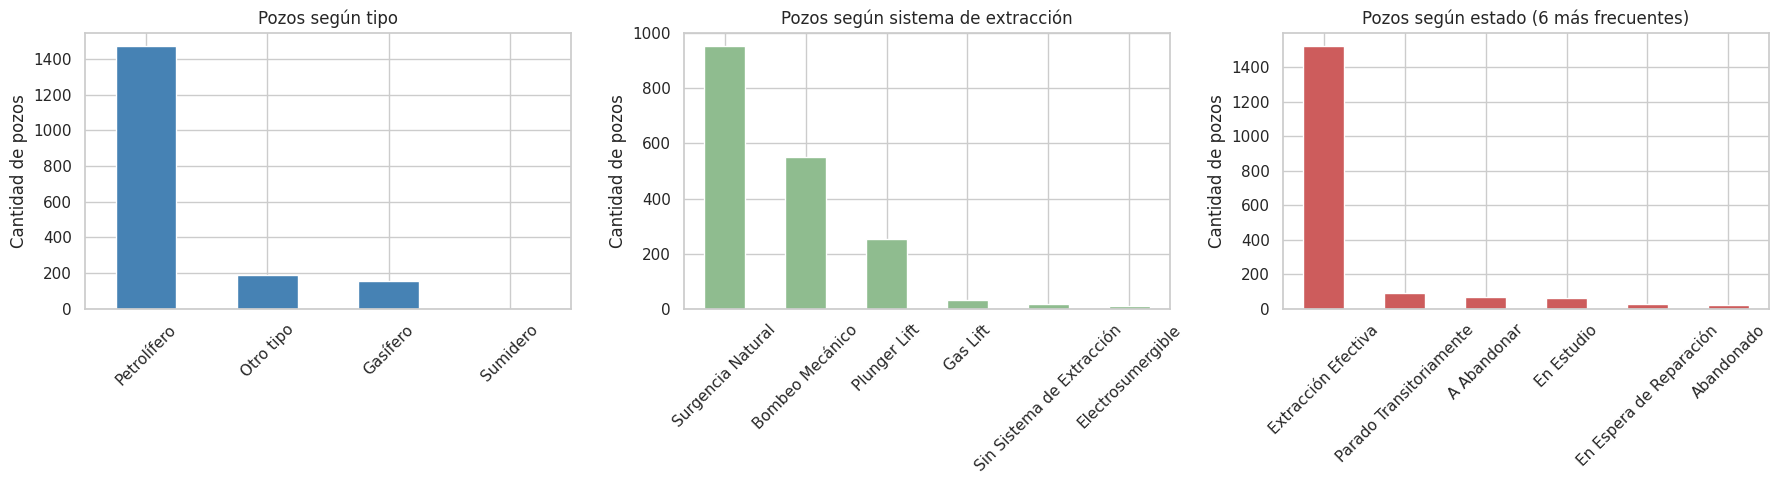

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

db_ypf["tipopozo"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Pozos según tipo")
axes[0].set_xlabel("")
axes[0].set_ylabel("Cantidad de pozos")
axes[0].tick_params(axis="x", rotation=45)

db_ypf["tipoextraccion"].value_counts().plot(kind="bar", ax=axes[1], color="darkseagreen")
axes[1].set_title("Pozos según sistema de extracción")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cantidad de pozos")
axes[1].tick_params(axis="x", rotation=45)

db_ypf["tipoestado"].value_counts().head(6).plot(kind="bar", ax=axes[2], color="indianred")
axes[2].set_title("Pozos según estado (6 más frecuentes)")
axes[2].set_xlabel("")
axes[2].set_ylabel("Cantidad de pozos")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
print("TIPO DE POZO")
print(db_ypf["tipopozo"].value_counts())
print("\nSISTEMA DE EXTRACCIÓN")
print(db_ypf["tipoextraccion"].value_counts())
print("\nESTADO")
print(db_ypf["tipoestado"].value_counts())

TIPO DE POZO
tipopozo
Petrolífero    1473
Otro tipo       188
Gasífero        155
Sumidero          2
Name: count, dtype: int64

SISTEMA DE EXTRACCIÓN
tipoextraccion
Surgencia Natural            953
Bombeo Mecánico              552
Plunger Lift                 254
Gas Lift                      32
Sin Sistema de Extracción     17
Electrosumergible             10
Name: count, dtype: int64

ESTADO
tipoestado
Extracción Efectiva        1523
Parado Transitoriamente      92
A Abandonar                  71
En Estudio                   63
En Espera de Reparación      26
Abandonado                   25
En Reserva de Gas             9
Abandono Temporario           4
Otras Situación Activo        2
En Inyección Efectiva         2
En Reparación                 1
Name: count, dtype: int64


In [ ]:
# Clasificación y subclasificación: variables no exploradas en la primera versión del análisis
print("CLASIFICACIÓN")
print(db_ypf["clasificacion"].value_counts())
print("\nSUBCLASIFICACIÓN")
print(db_ypf["subclasificacion"].value_counts())

CLASIFICACIÓN
clasificacion
EXPLOTACION    1747
EXPLORACION      65
SERVICIO          6
Name: count, dtype: int64

SUBCLASIFICACIÓN
subclasificacion
DESARROLLO     1742
EXPLORACION      64
CONTROL           6
AVANZADA          5
EXTENSION         1
Name: count, dtype: int64


In [ ]:
# Áreas
resumen_areas = (
    db_ypf.groupby("area")
    .agg(cantidad_pozos=("idpozo", "nunique"))
    .sort_values("cantidad_pozos", ascending=False)
)

print("Cantidad de áreas:", len(resumen_areas))
print("Total de pozos:   ", resumen_areas["cantidad_pozos"].sum())
resumen_areas

Cantidad de áreas: 28
Total de pozos:    1818


,cantidad_pozos
area,
LOMA CAMPANA,837
LA AMARGA CHICA,328
BANDURRIA SUR,219
EL OREJANO,95
LA ANGOSTURA SUR I,64
AGUADA DEL CHAÑAR,64
RINCON DEL MANGRULLO,58
AGUADA DE LA ARENA,41
BAJO DEL TORO NORTE,22


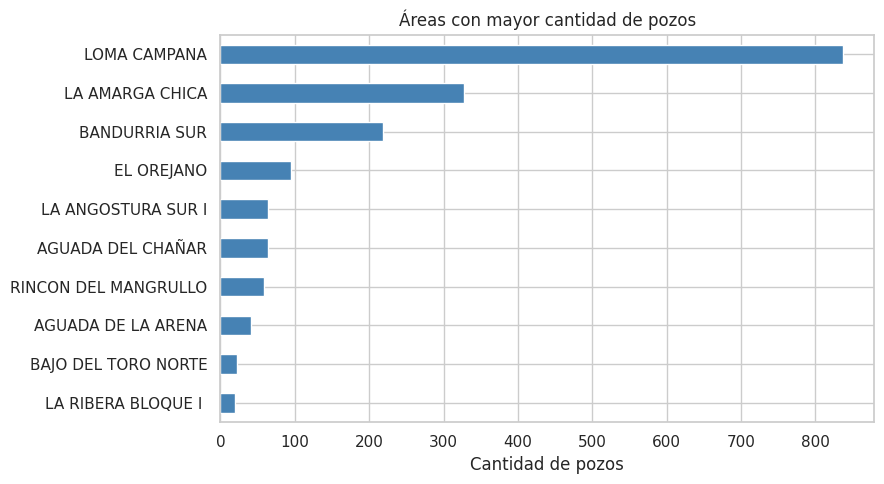

In [ ]:
resumen_areas.head(10).plot(
    kind="barh", figsize=(9, 5), legend=False, color="steelblue"
)
plt.gca().invert_yaxis()
plt.title("Áreas con mayor cantidad de pozos")
plt.xlabel("Cantidad de pozos")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 11.1 Distribución de la profundidad

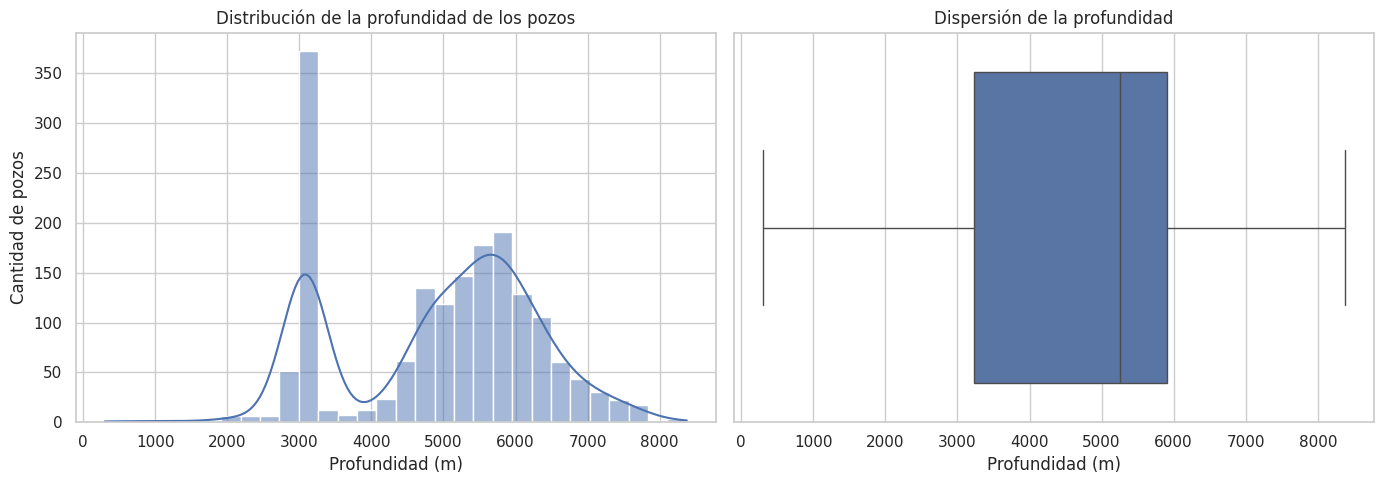

Asimetría de la profundidad: -0.312


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=db_ypf, x="profundidad_valida", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribución de la profundidad de los pozos")
axes[0].set_xlabel("Profundidad (m)")
axes[0].set_ylabel("Cantidad de pozos")

sns.boxplot(data=db_ypf, x="profundidad_valida", ax=axes[1])
axes[1].set_title("Dispersión de la profundidad")
axes[1].set_xlabel("Profundidad (m)")

plt.tight_layout()
plt.show()

print("Asimetría de la profundidad:", round(db_ypf["profundidad_valida"].skew(), 3))

La profundidad presenta más de una concentración de valores dentro del universo analizado.

Con las variables disponibles actualmente no puede atribuirse directamente este patrón a diferencias entre pozos verticales y horizontales. La variable `subclasificacion` describe categorías operativas o de desarrollo y no constituye una medida de geometría del pozo.

Por este motivo, la orientación horizontal o vertical no se inferirá a partir de la profundidad. Esta limitación se tendrá en cuenta al seleccionar las variables predictoras.

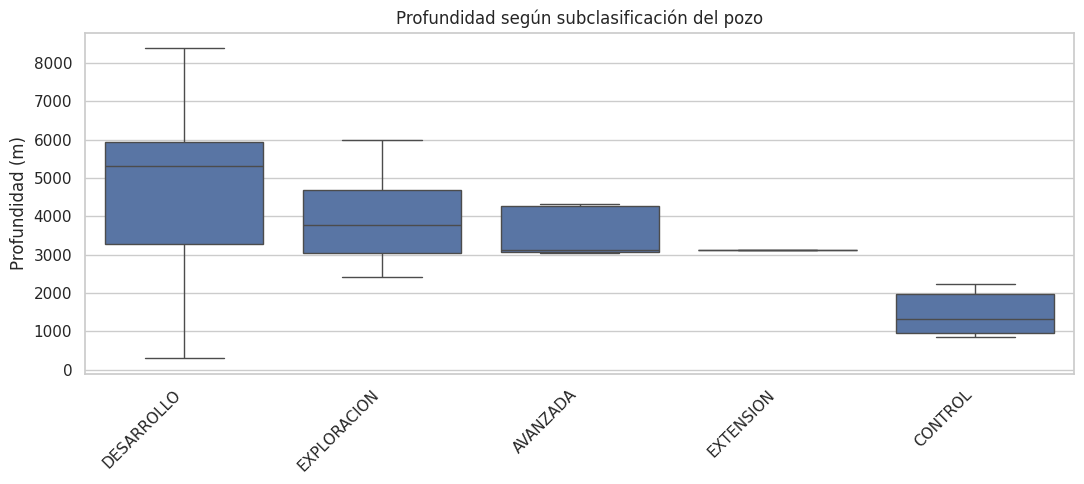

,count,mean,std,min,25%,50%,75%,max
subclasificacion,,,,,,,,
AVANZADA,5.0,3557.4,668.2,3040.0,3058.0,3112.0,4263.0,4314.0
CONTROL,6.0,1463.2,614.9,852.0,958.0,1327.5,1987.2,2230.0
DESARROLLO,1669.0,5010.0,1334.9,301.0,3275.0,5318.0,5942.0,8376.0
EXPLORACION,63.0,3908.3,941.5,2414.0,3047.0,3770.0,4697.0,5997.0
EXTENSION,1.0,3126.0,NaN,3126.0,3126.0,3126.0,3126.0,3126.0


In [ ]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=db_ypf, x="subclasificacion", y="profundidad_valida")
plt.title("Profundidad según subclasificación del pozo")
plt.xlabel("")
plt.ylabel("Profundidad (m)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

db_ypf.groupby("subclasificacion")["profundidad_valida"].describe().round(1)

### 11.2 Duraciones operativas

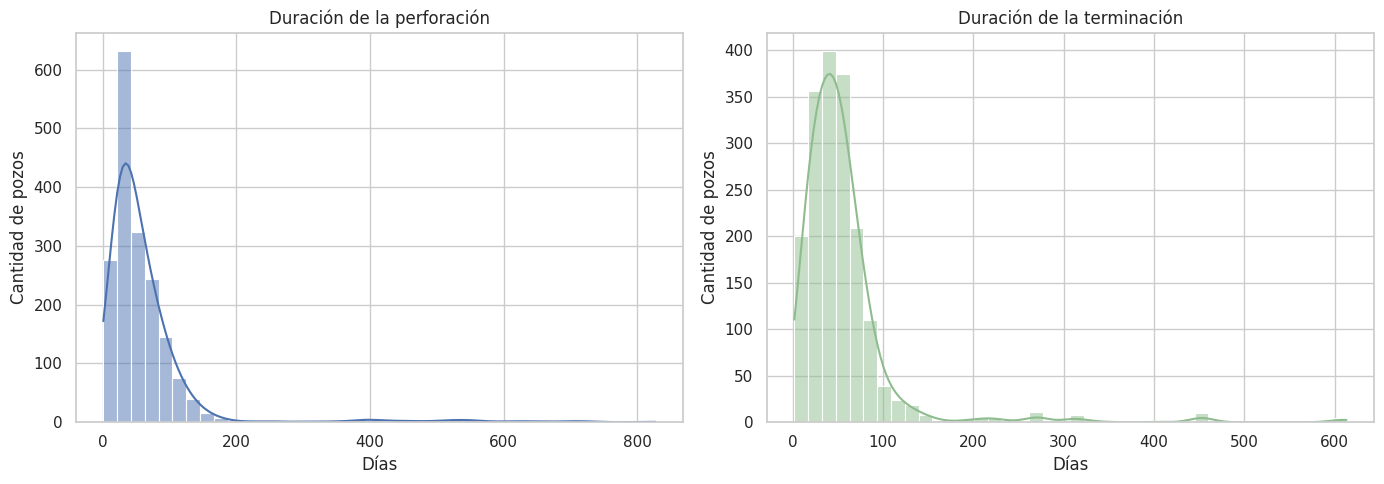

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=db_ypf, x="duracion_perforacion_valida", bins=40, kde=True, ax=axes[0])
axes[0].set_title("Duración de la perforación")
axes[0].set_xlabel("Días")
axes[0].set_ylabel("Cantidad de pozos")

sns.histplot(data=db_ypf, x="duracion_terminacion_valida", bins=40, kde=True,
             ax=axes[1], color="darkseagreen")
axes[1].set_title("Duración de la terminación")
axes[1].set_xlabel("Días")
axes[1].set_ylabel("Cantidad de pozos")

plt.tight_layout()
plt.show()

## 12. Análisis de las variables productivas

In [ ]:
db_prod_vm[variables_produccion].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
prod_pet,141920.0,568.58,1151.65,0.0,2.45,58.50,562.33,13076.13
prod_gas,141920.0,324.06,1120.66,0.0,5.77,43.19,171.17,40086.80
prod_agua,141920.0,227.21,624.56,0.0,0.02,15.60,136.90,28671.30


In [ ]:
# Diagnóstico de ceros, faltantes y asimetría
diagnostico = pd.DataFrame({
    "nulos": [db_prod_vm[v].isna().sum() for v in variables_produccion],
    "ceros": [(db_prod_vm[v] == 0).sum() for v in variables_produccion],
    "ceros_pct": [round((db_prod_vm[v] == 0).sum() / len(db_prod_vm) * 100, 2)
                  for v in variables_produccion],
    "negativos": [(db_prod_vm[v] < 0).sum() for v in variables_produccion],
    "asimetria": [round(db_prod_vm[v].skew(), 3) for v in variables_produccion],
}, index=variables_produccion)

diagnostico

,nulos,ceros,ceros_pct,negativos,asimetria
prod_pet,0,32728,23.06,0,3.345
prod_gas,0,27125,19.11,0,7.711
prod_agua,0,35349,24.91,0,6.487


In [ ]:
# ¿Los ceros responden a meses sin actividad o a pozos que producen un solo hidrocarburo?
situacion = pd.Series({
    "Solo petróleo": ((db_prod_vm["prod_pet"] > 0) & (db_prod_vm["prod_gas"] == 0)).sum(),
    "Solo gas": ((db_prod_vm["prod_pet"] == 0) & (db_prod_vm["prod_gas"] > 0)).sum(),
    "Petróleo y gas": ((db_prod_vm["prod_pet"] > 0) & (db_prod_vm["prod_gas"] > 0)).sum(),
    "Sin petróleo ni gas": ((db_prod_vm["prod_pet"] == 0) & (db_prod_vm["prod_gas"] == 0)).sum(),
})

resultado = pd.DataFrame({
    "registros": situacion,
    "porcentaje": (situacion / situacion.sum() * 100).round(2),
})
resultado

,registros,porcentaje
Solo petróleo,403,0.28
Solo gas,6006,4.23
Petróleo y gas,108789,76.66
Sin petróleo ni gas,26722,18.83


In [ ]:
# ¿Cuántos de los meses sin producción corresponden a meses sin actividad declarada?
sin_produccion = db_prod_vm[(db_prod_vm["prod_pet"] == 0) & (db_prod_vm["prod_gas"] == 0)]

print("Meses sin petróleo ni gas:", len(sin_produccion))
print("  de los cuales tienen tef = 0 (sin actividad):",
      (sin_produccion["tef"] == 0).sum())
print("  con tef > 0 pero producción nula:",
      (sin_produccion["tef"] > 0).sum())

Meses sin petróleo ni gas: 26722
  de los cuales tienen tef = 0 (sin actividad): 26632
  con tef > 0 pero producción nula: 90


La distinción es relevante: los meses con `tef = 0` corresponden a pozos **sin actividad** en el período y no deben interpretarse como baja productividad. Los meses con `tef > 0` y producción nula sí constituyen información productiva —el pozo operó y no produjo— y se conservan en el universo activo.

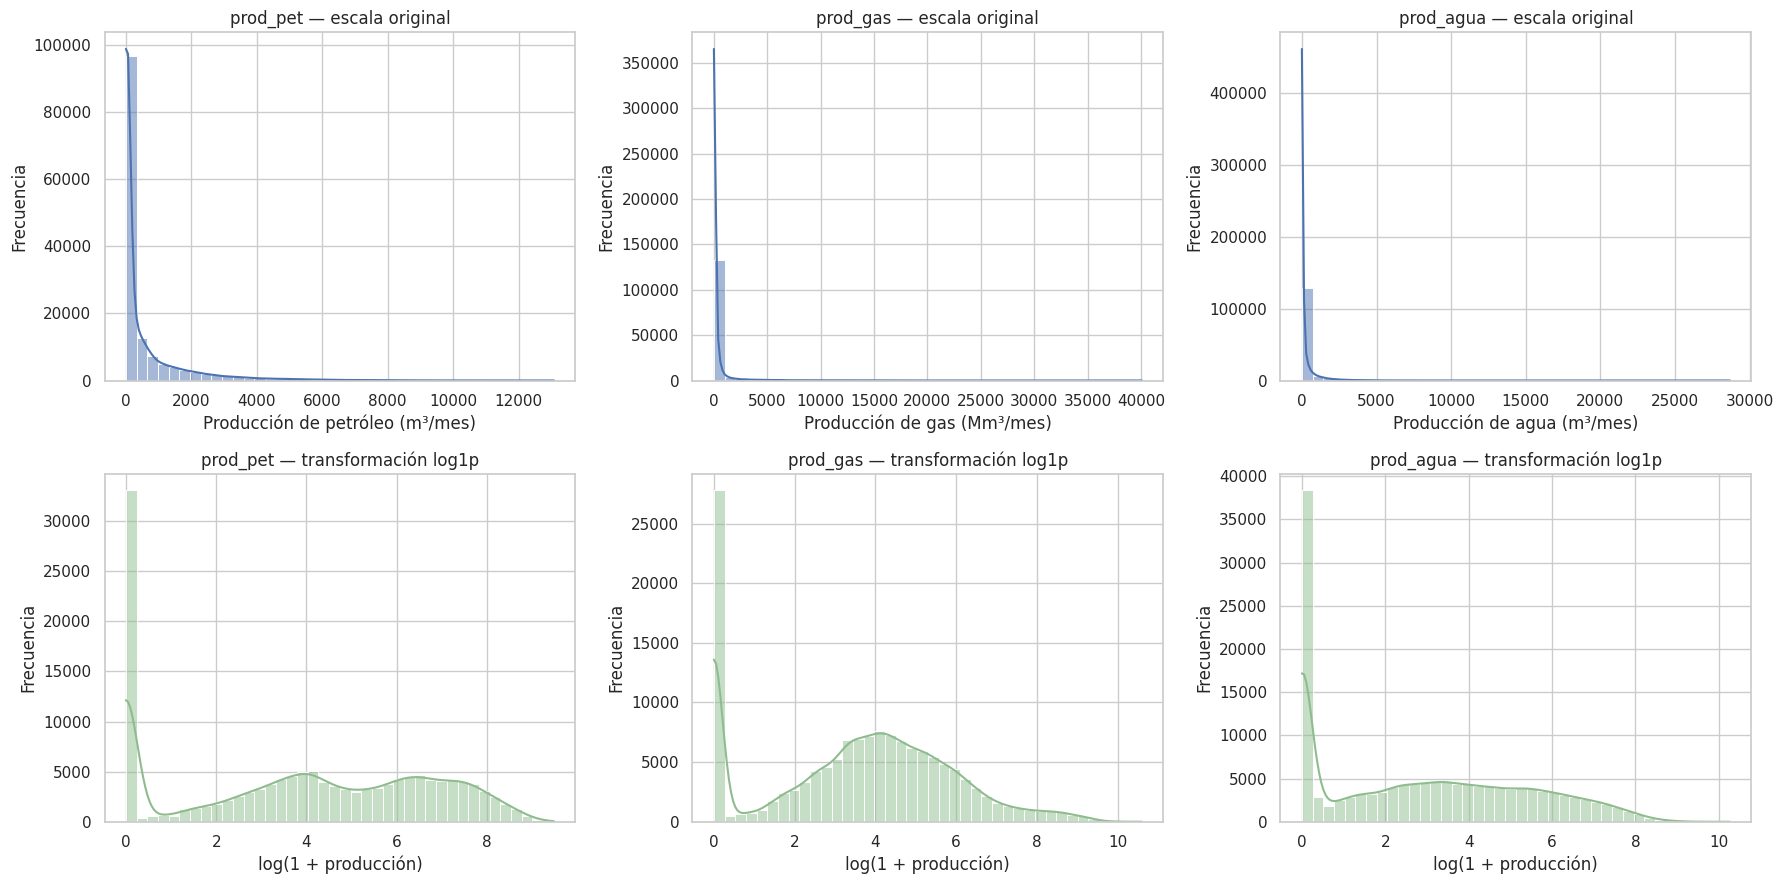

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for i, variable in enumerate(variables_produccion):
    sns.histplot(data=db_prod_vm, x=variable, bins=40, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{variable} — escala original")
    axes[0, i].set_ylabel("Frecuencia")

    sns.histplot(data=db_prod_vm, x=variable + "_log", bins=40, kde=True,
                 ax=axes[1, i], color="darkseagreen")
    axes[1, i].set_title(f"{variable} — transformación log1p")
    axes[1, i].set_ylabel("Frecuencia")

axes[0, 0].set_xlabel("Producción de petróleo (m³/mes)")
axes[0, 1].set_xlabel("Producción de gas (Mm³/mes)")
axes[0, 2].set_xlabel("Producción de agua (m³/mes)")
for j in range(3):
    axes[1, j].set_xlabel("log(1 + producción)")

plt.tight_layout()
plt.show()

En la escala original las tres variables presentan distribuciones
fuertemente asimétricas a la derecha. La transformación log1p reduce fuertemente la asimetría y permite distinguir mejor la concentración de observaciones en cero y la distribución de los valores positivos. Esto no implica normalidad.

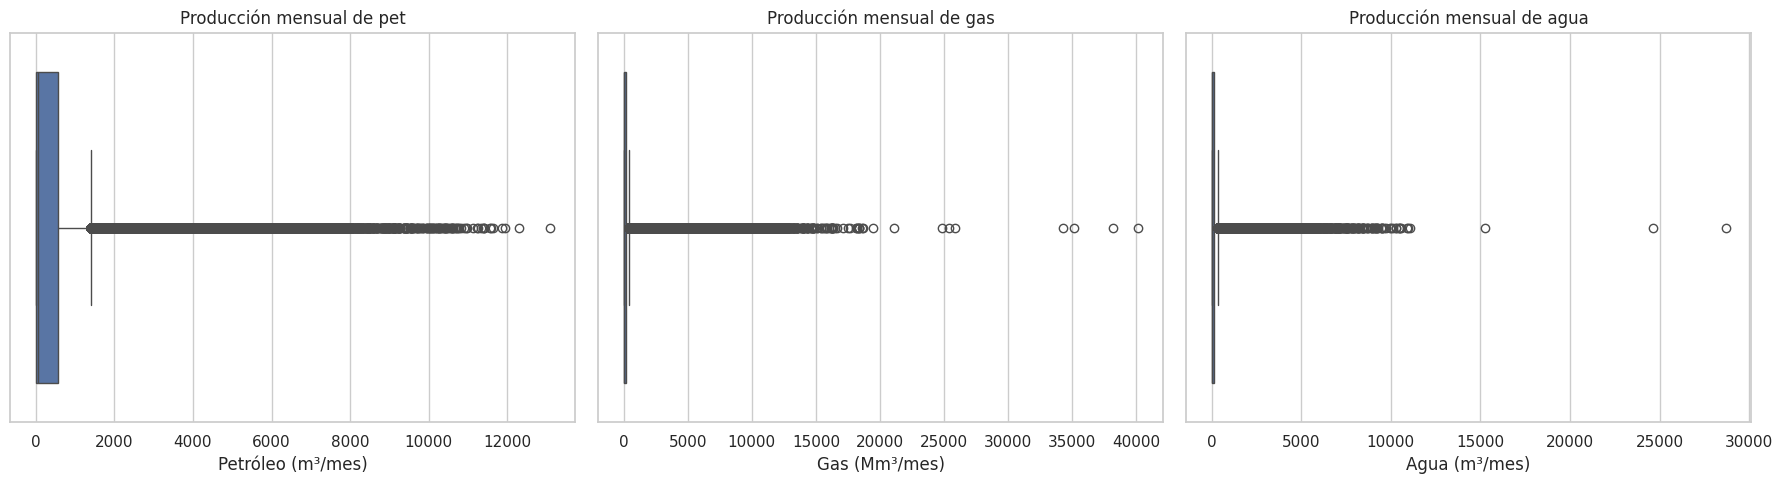

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
etiquetas = ["Petróleo (m³/mes)", "Gas (Mm³/mes)", "Agua (m³/mes)"]

for i, (variable, etiqueta) in enumerate(zip(variables_produccion, etiquetas)):
    sns.boxplot(data=db_prod_vm, x=variable, ax=axes[i])
    axes[i].set_title(f"Producción mensual de {variable.split('_')[1]}")
    axes[i].set_xlabel(etiqueta)

plt.tight_layout()
plt.show()

### 12.1 Sobre la detección de valores atípicos
Los boxplots muestran numerosos registros alejados del rango central. Se evalúa el criterio del rango intercuartílico (IQR) para dimensionar el fenómeno, teniendo presente una limitación importante: **el criterio IQR supone distribuciones aproximadamente simétricas**. Aplicado a variables con asimetría elevada y una masa relevante de ceros, tiende a clasificar como atípica una porción sustancial de los datos, lo que constituye un artefacto del método y no evidencia de error en los registros.

In [ ]:
def detectar_outliers_iqr(df, columna):
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)]

    return pd.Series({
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "limite_superior": round(limite_superior, 2),
        "registros_atipicos": len(outliers),
        "pct_del_total": round(len(outliers) / len(df) * 100, 2),
        "pozos_involucrados": outliers["idpozo"].nunique(),
    })

pd.DataFrame({v: detectar_outliers_iqr(db_prod_vm, v) for v in variables_produccion})

,prod_pet,prod_gas,prod_agua
Q1,2.45,5.77,0.02
Q3,562.33,171.17,136.90
IQR,559.88,165.40,136.88
limite_superior,1402.14,419.26,342.23
registros_atipicos,18957.00,18254.00,21951.00
pct_del_total,13.36,12.86,15.47
pozos_involucrados,1197.00,1368.00,1774.00


El criterio marca como atípica una fracción muy elevada de los registros, involucrando a la mayoría de los pozos. **No se eliminan observaciones sobre esta base.** En su lugar se aplica un criterio de plausibilidad física sobre el caudal diario, que sí permite identificar registros potencialmente erróneos.

In [ ]:
# Caudales diarios normalizados por tiempo efectivo

db_activos["caudal_pet"] = (
    db_activos["prod_pet"] / db_activos["tef"]
)

db_activos["caudal_gas"] = (
    db_activos["prod_gas"] / db_activos["tef"]
)

db_activos["caudal_agua"] = (
    db_activos["prod_agua"] / db_activos["tef"]
)

In [ ]:
## Criterio de plausibilidad: caudales diarios extremos dentro del universo activo
umbral_pet = db_activos["caudal_pet"].quantile(0.999)
umbral_gas = db_activos["caudal_gas"].quantile(0.999)

print(f"Percentil 99,9 del caudal de petróleo: {umbral_pet:.2f} m³/día")
print(f"Percentil 99,9 del caudal de gas:      {umbral_gas:.2f} Mm³/día")
print()

sospechosos = db_activos[
    (db_activos["caudal_pet"] > umbral_pet) | (db_activos["caudal_gas"] > umbral_gas)
]

print("Registros por encima del percentil 99,9:", len(sospechosos))
print("Pozos involucrados:", sospechosos["idpozo"].nunique())

sospechosos[["idpozo", "fecha", "tef", "prod_pet", "caudal_pet",
             "prod_gas", "caudal_gas"]].sort_values("caudal_pet", ascending=False).head(10)

Percentil 99,9 del caudal de petróleo: 304.76 m³/día
Percentil 99,9 del caudal de gas:      444.38 Mm³/día

Registros por encima del percentil 99,9: 232
Pozos involucrados: 109


,idpozo,fecha,tef,prod_pet,caudal_pet,prod_gas,caudal_gas
58920,154555,2016-09-01,0.01,23.89,2389.000000,0.00,0.000000
138504,166250,2025-11-01,0.02,23.55,1177.500000,4.09,204.500000
136984,165714,2026-07-01,0.13,85.60,658.461538,0.60,4.615385
77355,156552,2019-12-01,0.04,18.60,465.000000,0.00,0.000000
140735,166825,2026-01-01,30.83,13076.13,424.136555,5165.01,167.531949
140524,166808,2025-12-01,30.94,12288.66,397.177117,1586.52,51.277311
140608,166815,2025-11-01,29.90,11645.30,389.474916,1304.63,43.633110
110252,162024,2021-04-01,29.98,11550.42,385.270847,1027.55,34.274516
139102,166451,2025-07-01,31.00,11942.74,385.249677,1075.68,34.699355
141177,166932,2026-01-01,30.88,11865.34,384.240285,1492.48,48.331606


Estos registros se revisan individualmente antes de decidir cualquier tratamiento. Valores elevados de caudal son esperables en los primeros meses de un pozo no convencional, por lo que la decisión de conservarlos o corregirlos debe apoyarse en el contexto del pozo —en particular, en su antigüedad al momento del registro— y no únicamente en la magnitud del valor.

## 13. Variables operativas dinámicas
Antes de comparar la producción entre grupos es necesario determinar si los atributos usados para agrupar son **fijos** por pozo o **cambian a lo largo del tiempo**. Esta verificación condiciona la forma correcta de agrupar y la interpretación de los resultados.

In [ ]:
tipos_por_pozo = db_prod_vm.groupby("idpozo")["tipopozo"].nunique()
extraccion_por_pozo = db_prod_vm.groupby("idpozo")["tipoextraccion"].nunique()

resumen_dinamicas = pd.DataFrame({
    "un_solo_valor": [(tipos_por_pozo == 1).sum(), (extraccion_por_pozo == 1).sum()],
    "mas_de_un_valor": [(tipos_por_pozo > 1).sum(), (extraccion_por_pozo > 1).sum()],
}, index=["tipopozo", "tipoextraccion"])

resumen_dinamicas["pct_cambia"] = (
    resumen_dinamicas["mas_de_un_valor"] /
    (resumen_dinamicas["un_solo_valor"] + resumen_dinamicas["mas_de_un_valor"]) * 100
).round(2)

resumen_dinamicas

,un_solo_valor,mas_de_un_valor,pct_cambia
tipopozo,1391,427,23.49
tipoextraccion,733,1085,59.68


In [ ]:
# Combinaciones de tipos observadas en pozos que cambian de clasificación
combinaciones = (
    db_prod_vm.groupby("idpozo")["tipopozo"]
    .apply(lambda x: tuple(sorted(x.dropna().unique())))
)

combinaciones[combinaciones.apply(len) > 1].value_counts()

,count
tipopozo,
"(Otro tipo, Petrolífero)",315
"(Gasífero, Otro tipo)",96
"(Gasífero, Otro tipo, Petrolífero)",14
"(Gasífero, Petrolífero)",1
"(Otro tipo, Sumidero)",1


**Consecuencia metodológica.** Una proporción relevante de los pozos cambia de tipo y/o de sistema de extracción a lo largo de su historia. Por lo tanto:
- Los análisis comparativos por `tipopozo` y `tipoextraccion` se realizan **a nivel de registro mensual**, no a nivel de  pozo: cada mes se clasifica según el atributo vigente en ese período.
- Los resultados describen **asociaciones entre la configuración operativa vigente y la producción observada**, y no  relaciones causales: el sistema de extracción suele modificarse *como respuesta* a la evolución productiva del pozo,  de modo que la dirección de la relación no puede establecerse con este análisis.
- Existe además una diferencia entre la clasificación registrada en el dataset técnico (situación actual del pozo) y la  registrada mes a mes en el dataset de producción. Se utiliza esta última en los análisis productivos, por ser la  contemporánea a cada registro.

In [ ]:
# Comparación entre ambas fuentes de clasificación
clasif_tecnica = db_ypf["tipopozo"].value_counts().rename("dataset_tecnico_actual")
clasif_produccion = (
    db_prod_vm.groupby("tipopozo")["idpozo"].nunique().rename("pozos_con_algun_registro")
)

pd.concat([clasif_tecnica, clasif_produccion], axis=1)

,dataset_tecnico_actual,pozos_con_algun_registro
tipopozo,,
Petrolífero,1473,1587
Otro tipo,188,437
Gasífero,155,233
Sumidero,2,2


## 14. Comparaciones complementarias durante meses activos

Este bloque conserva comparaciones por tipo de pozo, sistema de extracción y área **solo para meses con actividad efectiva (`tef > 0`)**. Sirve para describir la producción durante la operación, pero no representa por sí solo la producción mensual observada incluyendo períodos sin actividad. La comparación principal con todos los meses registrados se presenta en la sección 16.

### 14.1 Por tipo de pozo

In [ ]:
def comparar_grupos(df, variable_grupo, variables=("prod_pet", "prod_gas", "prod_agua")):
    variables = list(variables)
    resumen = df.groupby(variable_grupo).agg(
        registros=("idpozo", "size"),
        pozos=("idpozo", "nunique"),
    )
    medias = df.groupby(variable_grupo)[variables].mean().round(2).add_suffix("_media")
    medianas = df.groupby(variable_grupo)[variables].median().round(2).add_suffix("_mediana")
    return pd.concat([resumen, medianas, medias], axis=1).sort_values("registros", ascending=False)


comparacion_tipo = comparar_grupos(db_activos, "tipopozo")
comparacion_tipo

,registros,pozos,prod_pet_mediana,prod_gas_mediana,prod_agua_mediana,prod_pet_media,prod_gas_media,prod_agua_media
tipopozo,,,,,,,,
Petrolífero,104348,1581,187.05,59.29,28.80,767.77,150.73,263.55
Gasífero,10878,231,0.00,1771.83,185.46,51.74,2781.22,435.22
Sumidero,43,1,0.00,0.00,0.00,0.00,0.00,0.00
Otro tipo,14,5,1203.72,490.57,512.14,1032.63,571.09,739.65


In [ ]:
# Contraste con el cálculo sin filtrar meses inactivos
sin_filtro = db_prod_vm.groupby("tipopozo")[variables_produccion].median().round(2)
con_filtro = db_activos.groupby("tipopozo")[variables_produccion].median().round(2)

comparacion_criterios = pd.concat(
    [sin_filtro.add_suffix("_todos_los_meses"), con_filtro.add_suffix("_meses_activos")],
    axis=1,
)
comparacion_criterios

,prod_pet_todos_los_meses,prod_gas_todos_los_meses,prod_agua_todos_los_meses,prod_pet_meses_activos,prod_gas_meses_activos,prod_agua_meses_activos
tipopozo,,,,,,
Gasífero,0.00,1229.10,114.66,0.00,1771.83,185.46
Otro tipo,0.00,0.00,0.00,1203.72,490.57,512.14
Petrolífero,127.58,50.03,21.76,187.05,59.29,28.80
Sumidero,0.00,0.00,0.00,0.00,0.00,0.00


Este contraste muestra cómo cambia la distribución cuando se incluyen meses registrados sin actividad efectiva. En la sección 16 se presentan conjuntamente la producción mensual observada, la cantidad de meses activos y los meses sin actividad confirmada; las métricas de meses activos quedan como complemento y no se interpretan como producción total real.

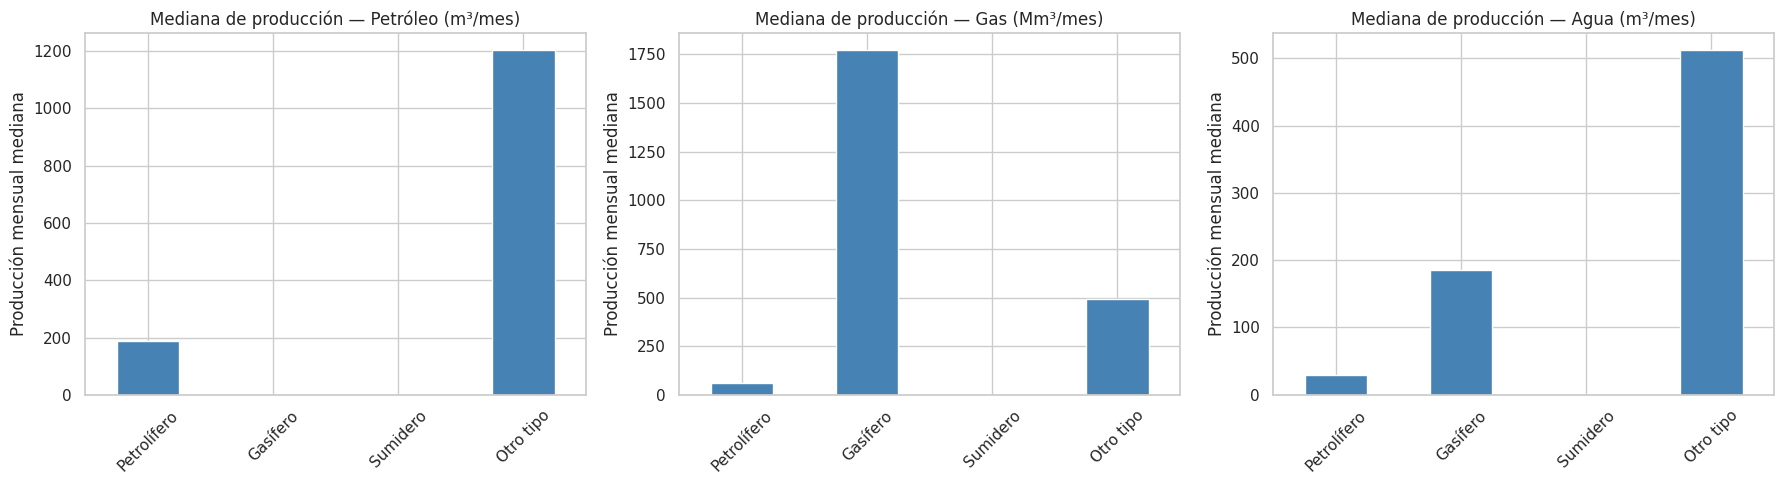

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
columnas = ["prod_pet_mediana", "prod_gas_mediana", "prod_agua_mediana"]
titulos = ["Petróleo (m³/mes)", "Gas (Mm³/mes)", "Agua (m³/mes)"]

for ax, columna, titulo in zip(axes, columnas, titulos):
    comparacion_tipo[columna].plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Mediana de producción — {titulo}")
    ax.set_xlabel("")
    ax.set_ylabel("Producción mensual mediana")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 14.2 Por sistema de extracción

In [ ]:
comparacion_extraccion = comparar_grupos(db_activos, "tipoextraccion")
comparacion_extraccion

,registros,pozos,prod_pet_mediana,prod_gas_mediana,prod_agua_mediana,prod_pet_media,prod_gas_media,prod_agua_media
tipoextraccion,,,,,,,,
Surgencia Natural,52715,1803,744.99,240.67,204.42,1301.62,802.38,551.38
Plunger Lift,35937,409,31.55,27.43,8.76,57.03,44.84,25.89
Bombeo Mecánico,24936,707,271.66,47.27,19.76,359.68,66.67,79.95
Gas Lift,1287,40,295.88,148.01,41.80,516.51,266.36,145.49
Bombeo Hidráulico,221,9,369.47,51.96,8.64,412.49,77.11,40.01
Electrosumergible,132,14,2087.19,393.96,212.02,2291.42,446.88,447.60
Sin Sistema de Extracción,43,1,0.00,0.00,0.00,0.00,0.00,0.00
Jet Pump,8,1,143.36,0.00,6.89,106.68,5.13,6.33
Pistoneo (Swabbing),4,1,0.50,0.00,1.66,0.48,0.00,1.42


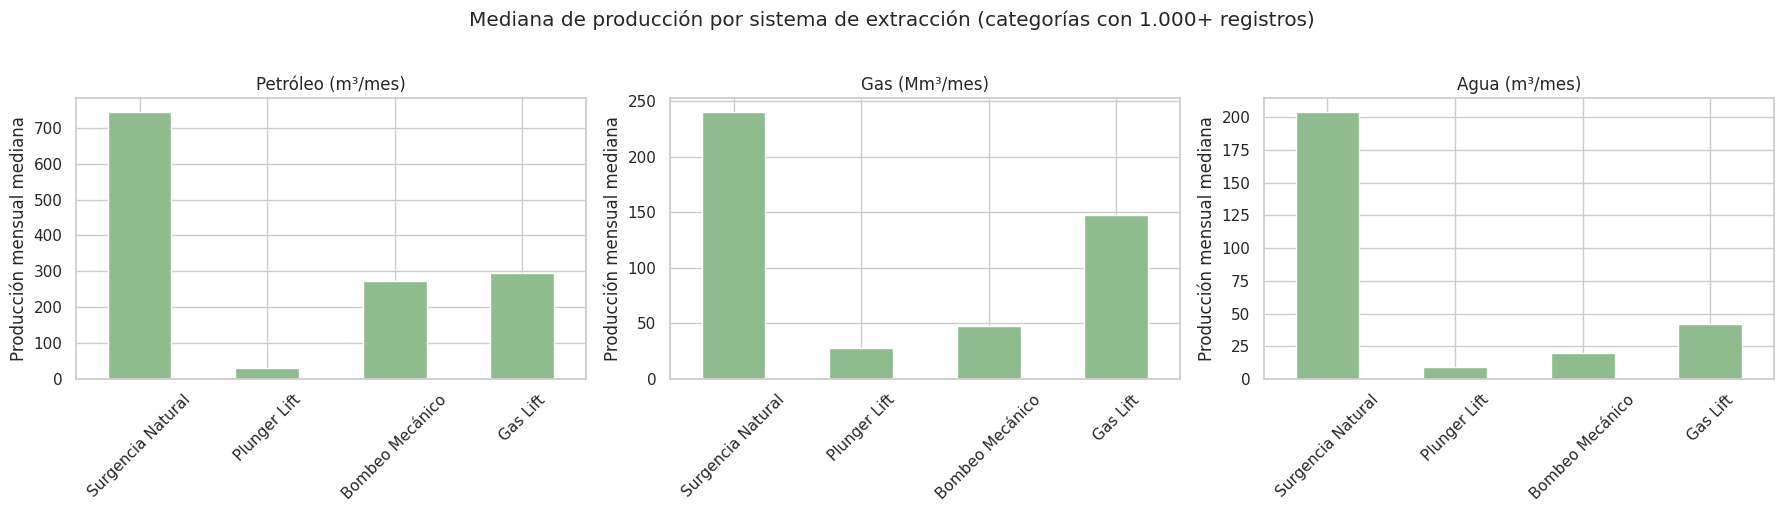

In [ ]:
# Se grafican únicamente las categorías con representatividad suficiente
extracciones_representativas = comparacion_extraccion[
    comparacion_extraccion["registros"] >= 1000
].index

grafico_extraccion = comparacion_extraccion.loc[extracciones_representativas]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, columna, titulo in zip(axes, columnas, titulos):
    grafico_extraccion[columna].plot(kind="bar", ax=ax, color="darkseagreen")
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("Producción mensual mediana")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Mediana de producción por sistema de extracción (categorías con 1.000+ registros)",
             y=1.02)
plt.tight_layout()
plt.show()

### 14.3 Por área
El área es un atributo del pozo y proviene del dataset técnico, por lo que se incorpora al dataset de producción mediante un `merge` por `idpozo`.

In [ ]:
pozos_area = db_ypf[["idpozo", "area", "profundidad_valida", "subclasificacion"]].copy()

registros_antes = len(db_activos)

db_activos = db_activos.merge(
    pozos_area,
    on="idpozo",
    how="left",
    validate="many_to_one",
    suffixes=("", "_tecnico")
)

print("Registros antes del merge: ", registros_antes)
print("Registros después del merge:", len(db_activos))
print("Pozos únicos:              ", db_activos["idpozo"].nunique())
print("Registros sin área:         ", db_activos["area"].isna().sum())


Registros antes del merge:  115283
Registros después del merge: 115283
Pozos únicos:               1805
Registros sin área:          0


Se utiliza un `merge` de tipo **left** porque la tabla principal del análisis es la de registros mensuales: se busca enriquecerla con los atributos del pozo sin alterar su cantidad de filas. La verificación posterior confirma que la cantidad de registros no cambió y que no quedaron valores sin asignar, lo que descarta duplicaciones por claves repetidas.

In [ ]:
areas_representativas = resumen_areas[resumen_areas["cantidad_pozos"] >= 50].index
print("Áreas incluidas en la comparación:", list(areas_representativas))

db_areas = db_activos[db_activos["area"].isin(areas_representativas)].copy()

print("\nRegistros incluidos:", len(db_areas))
print("Pozos incluidos:    ", db_areas["idpozo"].nunique())
print("Cobertura sobre el universo activo:",
      round(len(db_areas) / len(db_activos) * 100, 2), "%")

Áreas incluidas en la comparación: ['LOMA CAMPANA', 'LA AMARGA CHICA', 'BANDURRIA SUR', 'EL OREJANO', 'LA ANGOSTURA SUR I', 'AGUADA DEL CHAÑAR', 'RINCON DEL MANGRULLO']

Registros incluidos: 109424
Pozos incluidos:     1655
Cobertura sobre el universo activo: 94.92 %


In [ ]:
comparacion_area = comparar_grupos(db_areas, "area")
comparacion_area

,registros,pozos,prod_pet_mediana,prod_gas_mediana,prod_agua_mediana,prod_pet_media,prod_gas_media,prod_agua_media
area,,,,,,,,
LOMA CAMPANA,77742,832,76.90,42.66,15.24,470.95,114.16,116.92
LA AMARGA CHICA,14220,328,989.78,116.94,211.98,1480.89,179.40,591.40
BANDURRIA SUR,7532,219,1482.62,265.68,380.46,1886.93,351.71,825.11
EL OREJANO,5025,90,0.00,1275.86,146.29,7.46,2044.53,345.86
RINCON DEL MANGRULLO,2437,58,6.67,3533.33,278.21,19.85,4309.18,554.41
AGUADA DEL CHAÑAR,1469,64,1573.32,114.14,676.50,1873.73,143.05,986.56
LA ANGOSTURA SUR I,999,64,2586.71,579.64,344.47,2999.16,684.81,949.26


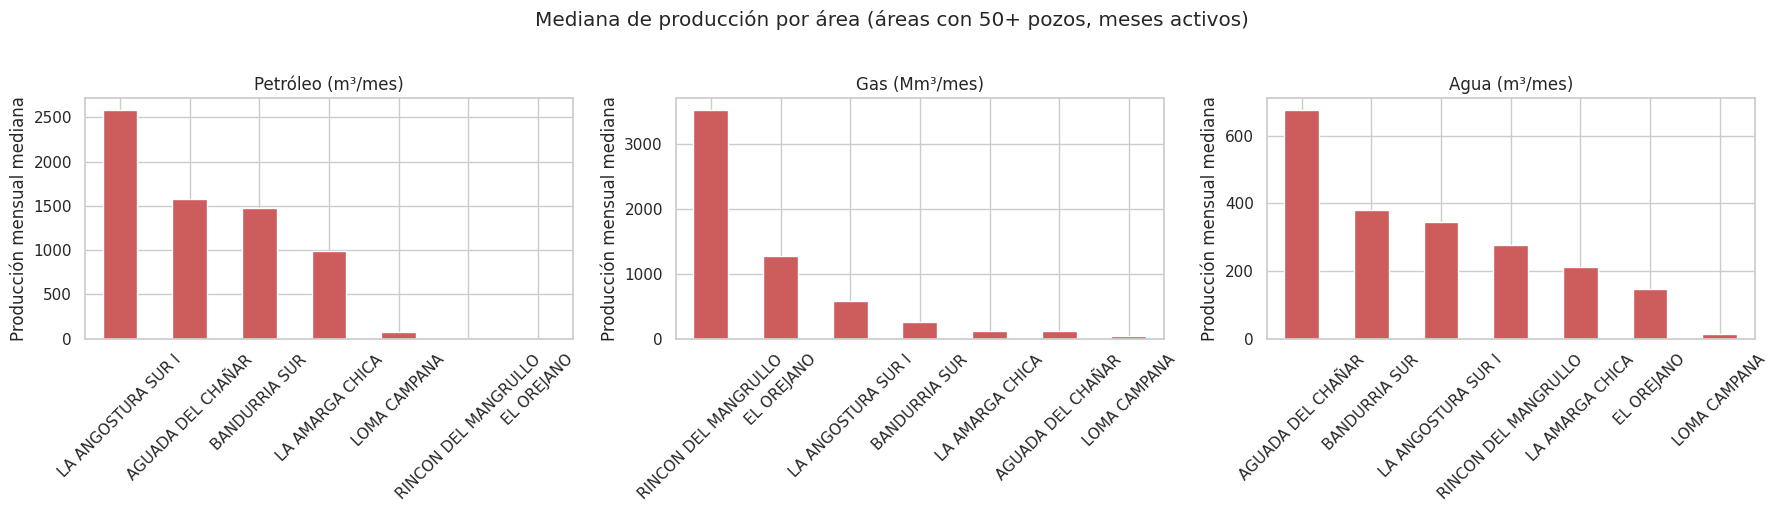

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, columna, titulo in zip(axes, columnas, titulos):
    comparacion_area[columna].sort_values(ascending=False).plot(
        kind="bar", ax=ax, color="indianred"
    )
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("Producción mensual mediana")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Mediana de producción por área (áreas con 50+ pozos, meses activos)", y=1.02)
plt.tight_layout()
plt.show()

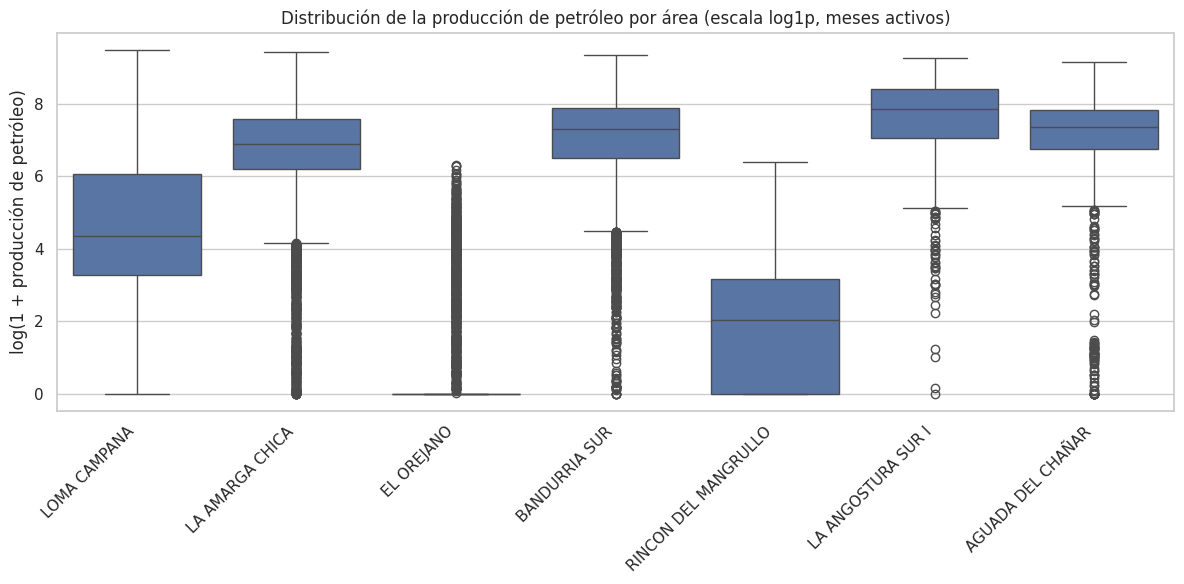

In [ ]:
# Dispersión dentro de cada área, no solo la medida central
plt.figure(figsize=(12, 6))
sns.boxplot(data=db_areas, x="area", y="prod_pet_log")
plt.title("Distribución de la producción de petróleo por área (escala log1p, meses activos)")
plt.xlabel("")
plt.ylabel("log(1 + producción de petróleo)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

El boxplot en escala logarítmica permite comparar las áreas considerando la **dispersión** y no únicamente la mediana. Áreas con medianas similares pueden presentar perfiles de variabilidad muy distintos, lo que resulta relevante para evaluar el riesgo asociado a cada una y para una eventual etapa de modelado.

## 15. Evolución temporal

Se describe la producción total reportada a lo largo del tiempo y, como complemento, la producción mensual por pozo activo. Los meses recientes se interpretan con cautela si la fuente todavía no está consolidada.

### 15.1 Evolución agregada de la producción (contexto)

#### Preparación del panel mensual y clasificación de actividad

Se conserva cada registro mensual del universo integrado. `tef = 0` junto con producción de petróleo, gas y agua igual a cero se clasifica como **sin actividad efectiva registrada**. Si `tef = 0` pero alguna producción es distinta de cero o falta, el mes queda **dudoso**: no se cuenta como una interrupción confirmada. La ausencia de una fila para un mes tampoco se convierte automáticamente en cero. Los valores de producción reportados en un registro dudoso se mantienen para la suma de producción, pero el registro se identifica por separado para revisión.

In [ ]:
# Incorporamos dimensiones técnicas sin cambiar la tabla mensual original
columnas_dimensiones = ["idpozo", "area", "yacimiento", "formacion"]
dimensiones_tecnicas = (
    db_ypf[columnas_dimensiones]
    .drop_duplicates(subset="idpozo")
    .rename(columns={
        "area": "area_tecnica",
        "yacimiento": "yacimiento_tecnico",
        "formacion": "formacion_tecnica",
    })
)

df_prod_grupo = db_prod_vm.merge(
    dimensiones_tecnicas,
    on="idpozo",
    how="left",
    validate="many_to_one",
)

variables_produccion = ["prod_pet", "prod_gas", "prod_agua"]
produccion_cero = df_prod_grupo[variables_produccion].eq(0).all(axis=1)
produccion_incompleta = df_prod_grupo[variables_produccion].isna().any(axis=1)

df_prod_grupo["mes_activo"] = df_prod_grupo["tef"].gt(0)
df_prod_grupo["mes_sin_actividad_clara"] = (
    df_prod_grupo["tef"].eq(0)
    & produccion_cero
    & ~produccion_incompleta
)
df_prod_grupo["mes_dudoso_tef0"] = (
    df_prod_grupo["tef"].eq(0)
    & (~produccion_cero | produccion_incompleta)
)

print("Registros mensuales:", len(df_prod_grupo))
print("Pozos únicos:", df_prod_grupo["idpozo"].nunique())
print("Meses con tef > 0:", int(df_prod_grupo["mes_activo"].sum()))
print("Meses tef = 0 y producción en cero:", int(df_prod_grupo["mes_sin_actividad_clara"].sum()))
print("Meses dudosos con tef = 0:", int(df_prod_grupo["mes_dudoso_tef0"].sum()))
print("Registros sin área técnica:", int(df_prod_grupo["area_tecnica"].isna().sum()))

Registros mensuales: 141920
Pozos únicos: 1818
Meses con tef > 0: 115283
Meses tef = 0 y producción en cero: 26631
Meses dudosos con tef = 0: 6
Registros sin área técnica: 0


In [ ]:
# Resumen temporal construido sobre todos los registros mensuales del universo integrado
serie_mensual = (
    df_prod_grupo.groupby("fecha")
    .agg(
        pet_total=("prod_pet", "sum"),
        gas_total=("prod_gas", "sum"),
        agua_total=("prod_agua", "sum"),
        pozos_reportados=("idpozo", "nunique"),
        meses_activos=("mes_activo", "sum"),
        meses_sin_actividad_clara=("mes_sin_actividad_clara", "sum"),
        registros_dudosos=("mes_dudoso_tef0", "sum"),
    )
)
serie_mensual.head()

,pet_total,gas_total,agua_total,pozos_reportados,meses_activos,meses_sin_actividad_clara,registros_dudosos
fecha,,,,,,,
2006-01-01,0.0,0.0,0.0,92,0,92,0
2006-02-01,0.0,0.0,0.0,92,0,92,0
2006-03-01,0.0,0.0,0.0,92,0,92,0
2006-04-01,0.0,0.0,0.0,92,0,92,0
2006-05-01,0.0,0.0,0.0,92,0,92,0


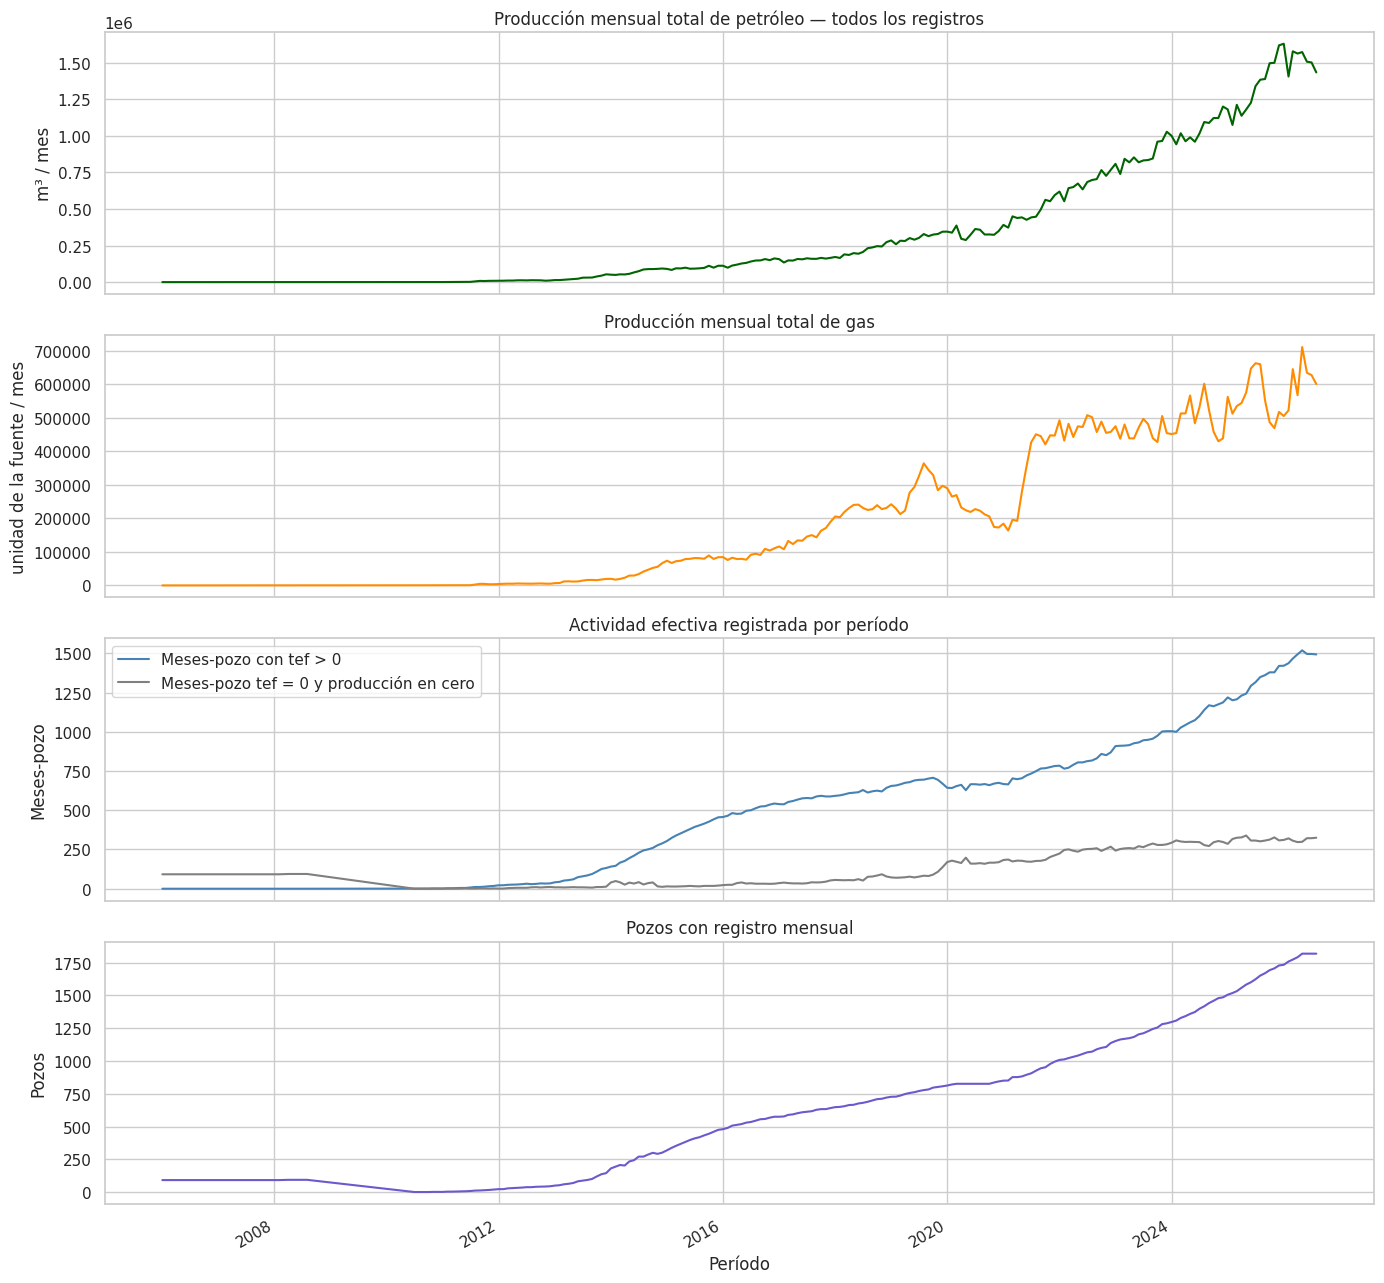

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True)

serie_mensual["pet_total"].plot(ax=axes[0], color="darkgreen")
axes[0].set_title("Producción mensual total de petróleo — todos los registros")
axes[0].set_ylabel("m³ / mes")

serie_mensual["gas_total"].plot(ax=axes[1], color="darkorange")
axes[1].set_title("Producción mensual total de gas")
axes[1].set_ylabel("unidad de la fuente / mes")

serie_mensual["meses_activos"].plot(ax=axes[2], label="Meses-pozo con tef > 0", color="steelblue")
serie_mensual["meses_sin_actividad_clara"].plot(ax=axes[2], label="Meses-pozo tef = 0 y producción en cero", color="gray")
axes[2].set_title("Actividad efectiva registrada por período")
axes[2].set_ylabel("Meses-pozo")
axes[2].legend()

serie_mensual["pozos_reportados"].plot(ax=axes[3], color="slateblue")
axes[3].set_title("Pozos con registro mensual")
axes[3].set_ylabel("Pozos")
axes[3].set_xlabel("Período")

plt.tight_layout()
plt.show()

La comparación entre la producción total y la cantidad de pozos permite distinguir si el crecimiento agregado responde a la **incorporación de nuevos pozos** o a una mejora en la productividad por pozo. Los últimos períodos deben leerse con cautela por la posible carga parcial de la fuente.

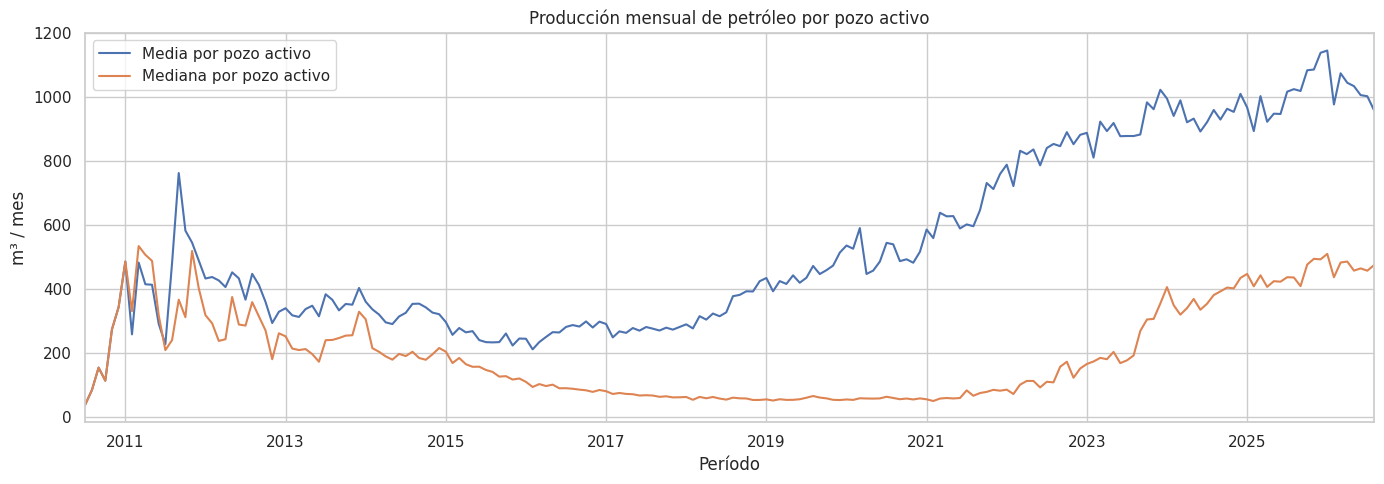

In [ ]:
# Producción media por pozo activo: aísla el efecto de la incorporación de pozos
serie_activos = db_activos.groupby("fecha").agg(
    pet_mediana=("prod_pet", "median"),
    pet_media=("prod_pet", "mean"),
    pozos=("idpozo", "nunique"),
)

fig, ax = plt.subplots(figsize=(14, 5))
serie_activos["pet_media"].plot(ax=ax, label="Media por pozo activo")
serie_activos["pet_mediana"].plot(ax=ax, label="Mediana por pozo activo")
ax.set_title("Producción mensual de petróleo por pozo activo")
ax.set_ylabel("m³ / mes")
ax.set_xlabel("Período")
ax.legend()
plt.tight_layout()
plt.show()

## 16. AED mensual incluyendo meses sin actividad efectiva

Esta es la comparación principal para el objetivo grupal. Se usan todos los registros mensuales disponibles, incluidos los meses claramente registrados sin actividad efectiva. Para cada período y dimensión se muestran producción total, cantidad de pozos, meses activos y meses sin actividad confirmada. También se informan media y mediana por registro pozo-mes; se leen junto con los tamaños de grupo porque las distribuciones son asimétricas. Petróleo, gas y agua se mantienen en columnas separadas.

In [ ]:
def resumen_mensual_por_dimension(df, dimension):
    """Resume producción por mes y categoría, conservando meses sin actividad."""
    return (
        df.groupby(["fecha", dimension], dropna=False)
        .agg(
            pozos_con_registro=("idpozo", "nunique"),
            registros_pozo_mes=("idpozo", "size"),
            meses_activos=("mes_activo", "sum"),
            meses_sin_actividad_clara=("mes_sin_actividad_clara", "sum"),
            meses_dudosos=("mes_dudoso_tef0", "sum"),
            petroleo_total=("prod_pet", "sum"),
            petroleo_media_por_registro=("prod_pet", "mean"),
            petroleo_mediana_por_registro=("prod_pet", "median"),
            gas_total=("prod_gas", "sum"),
            agua_total=("prod_agua", "sum"),
        )
        .reset_index()
        .sort_values(["fecha", dimension])
    )

resumen_area_mensual = resumen_mensual_por_dimension(df_prod_grupo, "area_tecnica")
resumen_yacimiento_mensual = resumen_mensual_por_dimension(df_prod_grupo, "yacimiento_tecnico")
resumen_formacion_mensual = resumen_mensual_por_dimension(df_prod_grupo, "formacion_tecnica")

print("Combinaciones mes-área con mayor producción total de petróleo:")
display(resumen_area_mensual.nlargest(10, "petroleo_total"))
print("Combinaciones mes-yacimiento con mayor producción total de petróleo:")
display(resumen_yacimiento_mensual.nlargest(10, "petroleo_total"))
print("Combinaciones mes-formación con mayor producción total de petróleo:")
display(resumen_formacion_mensual.nlargest(10, "petroleo_total"))

Combinaciones mes-área con mayor producción total de petróleo:


,fecha,area_tecnica,pozos_con_registro,registros_pozo_mes,meses_activos,meses_sin_actividad_clara,meses_dudosos,petroleo_total,petroleo_media_por_registro,petroleo_mediana_por_registro,gas_total,agua_total
3205,2026-01-01,LOMA CAMPANA,827,827,686,141,0,512176.63,619.318779,53.36,108342.48,142023.70
3179,2025-12-01,LOMA CAMPANA,827,827,688,139,0,510554.62,617.357461,53.84,109436.94,165003.86
2947,2025-03-01,LOMA CAMPANA,793,793,616,177,0,458407.55,578.067528,34.52,92214.12,92671.08
3257,2026-03-01,LOMA CAMPANA,829,829,689,140,0,452516.87,545.858709,47.15,103014.43,115989.88
3153,2025-11-01,LOMA CAMPANA,826,826,676,150,0,448557.76,543.048136,51.95,110370.27,156997.57
3310,2026-05-01,LOMA CAMPANA,837,837,694,143,0,438296.28,523.651470,47.75,109930.70,131062.69
3119,2025-10-01,LA AMARGA CHICA,297,297,284,13,0,435501.69,1466.335657,876.31,49612.27,249477.59
3249,2026-03-01,LA AMARGA CHICA,319,319,301,18,0,433407.06,1358.642821,798.75,54368.29,205393.46
2823,2024-10-01,LOMA CAMPANA,781,781,640,141,0,432651.95,553.971767,41.60,88301.82,110770.15
2873,2024-12-01,LOMA CAMPANA,781,781,644,137,0,431142.89,552.039552,35.50,97399.69,115600.11


Combinaciones mes-yacimiento con mayor producción total de petróleo:


,fecha,yacimiento_tecnico,pozos_con_registro,registros_pozo_mes,meses_activos,meses_sin_actividad_clara,meses_dudosos,petroleo_total,petroleo_media_por_registro,petroleo_mediana_por_registro,gas_total,agua_total
3521,2025-10-01,LA AMARGA CHICA,297,297,284,13,0,435501.69,1466.335657,876.310,49612.27,249477.59
3661,2026-03-01,LA AMARGA CHICA,319,319,301,18,0,433407.06,1358.642821,798.750,54368.29,205393.46
3689,2026-04-01,LA AMARGA CHICA,319,319,304,15,0,429284.29,1345.718777,800.920,52594.96,180980.00
3577,2025-12-01,LA AMARGA CHICA,305,305,290,15,0,428654.07,1405.423180,807.600,53893.41,224662.68
3605,2026-01-01,LA AMARGA CHICA,309,309,296,13,0,414097.68,1340.121942,741.450,53290.47,221794.67
3549,2025-11-01,LA AMARGA CHICA,303,303,284,19,0,406825.76,1342.659274,750.750,47709.05,195509.19
3778,2026-07-01,LA AMARGA CHICA,328,328,305,23,0,406419.95,1239.085213,732.280,50226.17,184889.36
3748,2026-06-01,LA AMARGA CHICA,328,328,312,16,0,395983.17,1207.265762,734.435,50973.76,189303.89
3614,2026-01-01,LOMA CAMPANA-LLL,633,633,548,85,0,390246.40,616.503002,37.230,91843.19,110751.73
3586,2025-12-01,LOMA CAMPANA-LLL,633,633,553,80,0,387519.74,612.195482,38.460,93626.07,130363.84


Combinaciones mes-formación con mayor producción total de petróleo:


,fecha,formacion_tecnica,pozos_con_registro,registros_pozo_mes,meses_activos,meses_sin_actividad_clara,meses_dudosos,petroleo_total,petroleo_media_por_registro,petroleo_mediana_por_registro,gas_total,agua_total
218,2026-01-01,vaca muerta,1733,1733,1421,311,1,1628409.67,939.647819,260.170,505202.60,678515.82
217,2025-12-01,vaca muerta,1728,1728,1420,308,0,1617379.72,935.983634,251.020,517398.30,662089.11
220,2026-03-01,vaca muerta,1773,1773,1467,306,0,1576708.60,889.288550,260.160,645004.66,692359.70
222,2026-05-01,vaca muerta,1818,1818,1519,299,0,1571587.08,864.459340,251.025,710969.73,718910.70
221,2026-04-01,vaca muerta,1791,1791,1494,297,0,1561485.94,871.851446,291.990,567376.15,706776.03
223,2026-06-01,vaca muerta,1818,1818,1496,322,0,1505798.62,828.272068,261.445,634139.02,690278.31
224,2026-07-01,vaca muerta,1818,1818,1496,322,0,1500653.04,825.441716,248.740,627317.09,649587.27
216,2025-11-01,vaca muerta,1706,1706,1379,327,0,1498450.29,878.341319,238.900,469180.16,639564.13
215,2025-10-01,vaca muerta,1692,1692,1379,313,0,1495180.89,883.676649,216.995,486895.09,696578.85
225,2026-08-01,vaca muerta,1818,1818,1493,325,0,1432700.19,788.063911,271.280,600648.29,569310.83


### 16.1 Lectura de los meses sin actividad

`meses_sin_actividad_clara` cuenta registros con `tef = 0` y producción de petróleo, gas y agua en cero. No identifica por sí solo la causa del mes sin actividad. Los registros marcados como dudosos se informan aparte y no se usan para afirmar que hubo una interrupción. El resumen conserva la producción reportada en esos registros dudosos; su clasificación operativa queda pendiente de revisión.

In [ ]:
# Proporción mensual de registros sin actividad efectiva confirmada por área
resumen_actividad_area = resumen_area_mensual.copy()
resumen_actividad_area["pct_meses_sin_actividad"] = (
    resumen_actividad_area["meses_sin_actividad_clara"]
    / resumen_actividad_area["registros_pozo_mes"]
    * 100
).round(2)

resumen_actividad_area[[
    "fecha", "area_tecnica", "pozos_con_registro", "registros_pozo_mes",
    "meses_activos", "meses_sin_actividad_clara", "meses_dudosos",
    "pct_meses_sin_actividad", "petroleo_total",
]].head(15)

,fecha,area_tecnica,pozos_con_registro,registros_pozo_mes,meses_activos,meses_sin_actividad_clara,meses_dudosos,pct_meses_sin_actividad,petroleo_total
0,2006-01-01,BANDURRIA SUR,2,2,0,2,0,100.0,0.0
1,2006-01-01,LOMA CAMPANA,86,86,0,86,0,100.0,0.0
2,2006-01-01,LOMA LA LATA - SIERRA BARROSA,2,2,0,2,0,100.0,0.0
3,2006-01-01,NARAMBUENA,1,1,0,1,0,100.0,0.0
4,2006-01-01,VALLE DEL RIO GRANDE,1,1,0,1,0,100.0,0.0
5,2006-02-01,BANDURRIA SUR,2,2,0,2,0,100.0,0.0
6,2006-02-01,LOMA CAMPANA,86,86,0,86,0,100.0,0.0
7,2006-02-01,LOMA LA LATA - SIERRA BARROSA,2,2,0,2,0,100.0,0.0
8,2006-02-01,NARAMBUENA,1,1,0,1,0,100.0,0.0
9,2006-02-01,VALLE DEL RIO GRANDE,1,1,0,1,0,100.0,0.0


### 16.2 Evolución por área

Para facilitar la lectura se grafican las áreas con mayor cantidad de pozos en el universo integrado. La producción total muestra el volumen agregado de cada área; debe leerse junto con la cantidad de pozos y meses registrados. No se interpreta como productividad individual ni como efecto causal del área.

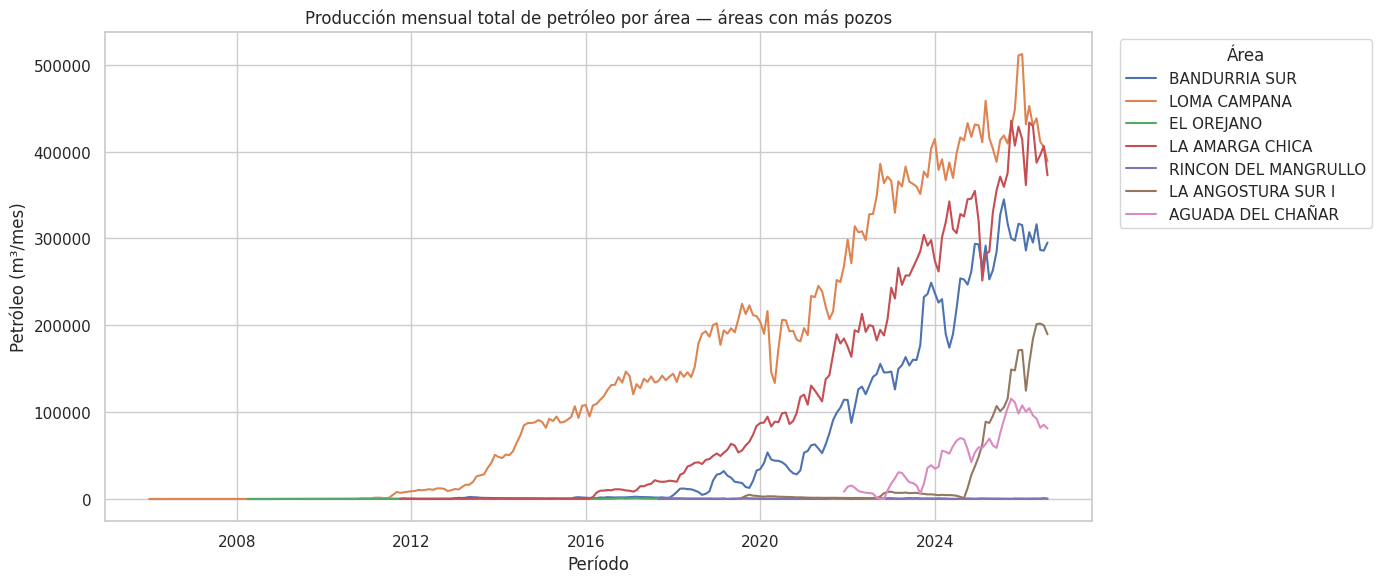

In [ ]:
# Seleccionamos las áreas con más pozos para evitar un gráfico ilegible
areas_principales = (
    df_prod_grupo.groupby("area_tecnica")["idpozo"]
    .nunique()
    .sort_values(ascending=False)
    .head(7)
    .index
)

grafico_area = resumen_area_mensual[
    resumen_area_mensual["area_tecnica"].isin(areas_principales)
]

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=grafico_area,
    x="fecha",
    y="petroleo_total",
    hue="area_tecnica",
)
plt.title("Producción mensual total de petróleo por área — áreas con más pozos")
plt.xlabel("Período")
plt.ylabel("Petróleo (m³/mes)")
plt.legend(title="Área", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Anexo A. Modelado predictivo previo a 24 meses

Este bloque se conserva como material de referencia del notebook original. No forma parte de la pregunta principal de esta versión, que se centra en el análisis descriptivo de la producción mensual incluyendo los meses registrados sin actividad efectiva. La cohorte predictiva de este anexo exige actividad efectiva en cada uno de los 24 meses y, por lo tanto, responde a una pregunta distinta y condicionada a esa selección.

In [ ]:
prod_24m = (
    db_24_validos
    .groupby("idpozo", as_index=False)
    .agg(
        pet_24m=("prod_pet", "sum"),
        gas_24m=("prod_gas", "sum"),
        agua_24m=("prod_agua", "sum")
    )
)

print("Filas:", len(prod_24m))
print("Pozos únicos:", prod_24m["idpozo"].nunique())

prod_24m.head()

Filas: 1150
Pozos únicos: 1150


,idpozo,pet_24m,gas_24m,agua_24m
0,135484,7188.28,1133.35,1800.35
1,135803,5980.11,1922.57,1283.68
2,135925,1146.19,5506.03,1198.00
3,136060,12019.41,12000.21,6632.72
4,136203,12063.60,9829.69,6831.77


In [ ]:
print("Estadísticos de pet_24m:")
display(prod_24m["pet_24m"].describe())

print(
    "\nPozos con pet_24m = 0:",
    (prod_24m["pet_24m"] == 0).sum()
)

print(
    "Pozos con pet_24m > 0:",
    (prod_24m["pet_24m"] > 0).sum()
)

print(
    "Pozos con pet_24m < 0:",
    (prod_24m["pet_24m"] < 0).sum()
)

Estadísticos de pet_24m:


,pet_24m
count,1150.000000
mean,33793.021991
std,29300.847357
min,0.000000
25%,5634.262500
50%,29546.735000
75%,57552.225000
max,144062.930000



Pozos con pet_24m = 0: 30
Pozos con pet_24m > 0: 1120
Pozos con pet_24m < 0: 0


In [ ]:
pozos_pet_cero_mes1 = mes_1.loc[
    mes_1["prod_pet"] == 0,
    "idpozo"
]

auditoria_79 = prod_24m[
    prod_24m["idpozo"].isin(pozos_pet_cero_mes1)
].copy()

print("Pozos auditados:", len(auditoria_79))

print(
    "Con petróleo acumulado > 0 a 24 meses:",
    (auditoria_79["pet_24m"] > 0).sum()
)

print(
    "Con petróleo acumulado = 0 a 24 meses:",
    (auditoria_79["pet_24m"] == 0).sum()
)

display(auditoria_79["pet_24m"].describe())

Pozos auditados: 79
Con petróleo acumulado > 0 a 24 meses: 49
Con petróleo acumulado = 0 a 24 meses: 30


,pet_24m
count,79.000000
mean,1703.104684
std,4542.414231
min,0.000000
25%,0.000000
50%,31.970000
75%,944.650000
max,32474.460000


In [ ]:
pet_positivo = db_24_validos[
    (db_24_validos["idpozo"].isin(pozos_pet_cero_mes1)) &
    (db_24_validos["prod_pet"] > 0)
].copy()

primer_mes_pet = (
    pet_positivo
    .groupby("idpozo")["mes_desde_inicio_activo"]
    .min()
    .rename("primer_mes_pet_positivo")
)

auditoria_79 = auditoria_79.merge(
    primer_mes_pet,
    on="idpozo",
    how="left"
)

auditoria_79[
    "primer_mes_pet_positivo"
].value_counts(
    dropna=False
).sort_index()

,count
primer_mes_pet_positivo,
2,17
3,8
4,3
6,2
7,6
8,2
9,2
10,1
12,3


In [ ]:
# Cantidad de meses con producción positiva de petróleo por pozo

auditoria_petroleo = (
    db_24_validos
    .groupby("idpozo")
    .agg(
        meses_pet_positivo=(
            "prod_pet",
            lambda x: (x > 0).sum()
        ),
        pet_24m=("prod_pet", "sum"),
        gas_24m=("prod_gas", "sum")
    )
)

print("Pozos totales:", len(auditoria_petroleo))

print(
    "Petróleo positivo los 24 meses:",
    (auditoria_petroleo["meses_pet_positivo"] == 24).sum()
)

print(
    "Petróleo positivo entre 1 y 23 meses:",
    auditoria_petroleo[
        "meses_pet_positivo"
    ].between(1, 23).sum()
)

print(
    "Petróleo igual a cero durante los 24 meses:",
    (auditoria_petroleo["meses_pet_positivo"] == 0).sum()
)

auditoria_petroleo[
    "meses_pet_positivo"
].describe()

Pozos totales: 1150
Petróleo positivo los 24 meses: 1057
Petróleo positivo entre 1 y 23 meses: 63
Petróleo igual a cero durante los 24 meses: 30


,meses_pet_positivo
count,1150.000000
mean,22.867826
std,4.639662
min,0.000000
25%,24.000000
50%,24.000000
75%,24.000000
max,24.000000


In [ ]:
pozos_pet_24_cero = auditoria_petroleo[
    auditoria_petroleo["pet_24m"] == 0
].index

revision_ceros = db_24_validos[
    db_24_validos["idpozo"].isin(pozos_pet_24_cero)
].copy()

(
    revision_ceros[
        revision_ceros["mes_desde_inicio_activo"] == 1
    ]["tipopozo"]
    .value_counts(dropna=False)
)

,count
tipopozo,
Gasífero,29
Sumidero,1


In [ ]:
auditoria_petroleo.loc[
    pozos_pet_24_cero,
    ["pet_24m", "gas_24m", "meses_pet_positivo"]
].describe()

,pet_24m,gas_24m,meses_pet_positivo
count,30.0,30.000000,30.0
mean,0.0,103993.528000,0.0
std,0.0,61146.126169,0.0
min,0.0,0.000000,0.0
25%,0.0,46418.905000,0.0
50%,0.0,109941.470000,0.0
75%,0.0,148232.132500,0.0
max,0.0,222258.390000,0.0


### 16.1 Análisis de la variable objetivo

La producción acumulada de petróleo durante los primeros 24 meses presenta una elevada variabilidad entre pozos.

Para los 1.150 pozos de la cohorte, la mediana de producción acumulada es de 29.546,74, mientras que la media es de 33.793,02.

Se identificaron 79 pozos con producción de petróleo igual a cero durante el primer mes. Sin embargo, 49 de ellos registraron producción positiva de petróleo posteriormente dentro de la ventana analizada.

Por esta razón, un valor de producción de petróleo igual a cero en el primer mes no se utiliza como criterio automático de exclusión.

La cohorte continúa definiéndose mediante el criterio de actividad efectiva (`tef > 0`) durante 24 meses calendario consecutivos.

### 16.2 Definición final de la cohorte de modelado

La cohorte final está compuesta por 1.150 pozos con 24 meses calendario consecutivos de actividad efectiva (`tef > 0`).

Al analizar específicamente la producción de petróleo se observa que:

- 1.057 pozos presentan producción positiva de petróleo durante los 24 meses;
- 63 pozos presentan producción positiva entre 1 y 23 meses;
- 30 pozos no registran producción de petróleo durante la ventana analizada.

Los pozos con producción de petróleo igual a cero no se eliminan, ya que cumplen el criterio de actividad efectiva y representan resultados posibles dentro del universo analizado.

Por lo tanto, los 1.150 pozos se mantienen para la etapa de modelado supervisado.

La variable objetivo del problema de regresión será `pet_24m`, correspondiente a la producción acumulada de petróleo durante los primeros 24 meses consecutivos de actividad efectiva.

##17. Dataset para Machine Learning

 Primero auditamos qué variables técnicas tenemos

In [ ]:
print(db_ypf.columns.tolist())

['sigla', 'idpozo', 'area', 'cod_area', 'empresa', 'yacimiento', 'cod_yacimiento', 'formacion', 'cuenca', 'provincia', 'cota', 'profundidad', 'clasificacion', 'subclasificacion', 'tipo_recurso', 'sub_tipo_recurso', 'gasplus', 'tipopozo', 'tipoextraccion', 'tipoestado', 'adjiv_fecha_inicio_perf', 'adjiv_fecha_fin_perf', 'adjiv_fecha_inicio_term', 'adjiv_fecha_fin_term', 'geojson', 'geom', 'duracion_perforacion_dias', 'duracion_terminacion_dias', 'duracion_perforacion_valida', 'duracion_terminacion_valida', 'profundidad_valida']


In [ ]:
columnas_candidatas = [
    "idpozo",
    "area",
    "cota",
    "profundidad",
    "profundidad_valida",
    "clasificacion",
    "subclasificacion",
    "tipopozo",
    "tipoextraccion",
    "tipoestado",
    "adjiv_fecha_inicio_perf",
    "adjiv_fecha_fin_perf",
    "adjiv_fecha_inicio_term",
    "adjiv_fecha_fin_term",
    "duracion_perforacion_dias",
    "duracion_terminacion_dias"
]

print("COLUMNAS DISPONIBLES:")
for col in columnas_candidatas:
    if col in db_ypf.columns:
        print("✓", col)

print("\nCOLUMNAS NO ENCONTRADAS:")
for col in columnas_candidatas:
    if col not in db_ypf.columns:
        print("✗", col)

COLUMNAS DISPONIBLES:
✓ idpozo
✓ area
✓ cota
✓ profundidad
✓ profundidad_valida
✓ clasificacion
✓ subclasificacion
✓ tipopozo
✓ tipoextraccion
✓ tipoestado
✓ adjiv_fecha_inicio_perf
✓ adjiv_fecha_fin_perf
✓ adjiv_fecha_inicio_term
✓ adjiv_fecha_fin_term
✓ duracion_perforacion_dias
✓ duracion_terminacion_dias

COLUMNAS NO ENCONTRADAS:


### 17.1 Momento de predicción y prevención de fuga de información

El modelo busca estimar la producción acumulada de petróleo durante los primeros 24 meses de actividad.

Por este motivo, las variables predictoras deben corresponder a información disponible al comienzo de la ventana productiva o antes de ella.

No se utilizarán como variables explicativas datos productivos generados durante los 24 meses que se desean predecir, ya que esto produciría fuga de información (`data leakage`).

pet_24m          ← es el target

Por ejemplo, variables como la producción de petróleo del mes 12, la producción acumulada de gas a 24 meses o el pico de producción no pueden utilizarse para predecir `pet_24m`, porque contienen información futura respecto del momento de predicción.

In [ ]:
inicio_modelo = (
    db_24_validos
    .groupby("idpozo", as_index=False)
    .agg(
        fecha_inicio_activo=("fecha_inicio_activo", "first")
    )
)

print(inicio_modelo.shape)
inicio_modelo.head()

(1150, 2)


,idpozo,fecha_inicio_activo
0,135484,2011-02-01
1,135803,2011-04-01
2,135925,2011-05-01
3,136060,2011-07-01
4,136203,2011-07-01


In [ ]:
auditoria_fechas = inicio_modelo.merge(
    db_ypf[
        [
            "idpozo",
            "adjiv_fecha_fin_perf",
            "adjiv_fecha_fin_term"
        ]
    ],
    on="idpozo",
    how="left",
    validate="one_to_one"
)

In [ ]:
print(
    "Fin perforación posterior al inicio activo:",
    (
        auditoria_fechas["adjiv_fecha_fin_perf"]
        > auditoria_fechas["fecha_inicio_activo"]
    ).sum()
)

print(
    "Fin terminación posterior al inicio activo:",
    (
        auditoria_fechas["adjiv_fecha_fin_term"]
        > auditoria_fechas["fecha_inicio_activo"]
    ).sum()
)

print(
    "Fin perforación faltante:",
    auditoria_fechas["adjiv_fecha_fin_perf"].isna().sum()
)

print(
    "Fin terminación faltante:",
    auditoria_fechas["adjiv_fecha_fin_term"].isna().sum()
)

Fin perforación posterior al inicio activo: 4
Fin terminación posterior al inicio activo: 824
Fin perforación faltante: 0
Fin terminación faltante: 13


### 17.2 Selección de variables predictoras disponibles al inicio

Para evitar fuga de información, se seleccionan únicamente variables que puedan considerarse disponibles al comienzo de la ventana productiva que se desea predecir.

La auditoría temporal mostró que la fecha de fin de terminación es posterior al inicio activo en 824 de los 1.150 pozos. Por este motivo, la duración de terminación no se utilizará inicialmente como variable predictora.

La fecha de fin de perforación es posterior al inicio activo solamente en 4 pozos. Para esos casos, la ***duración de perforación*** se tratará como información no disponible en el momento de predicción y se representará como valor faltante.

También se excluyen inicialmente `tipoextraccion`, `tipoestado` y `tipopozo` provenientes del registro técnico general, ya que durante el AED se observó que algunas de estas características pueden cambiar a lo largo de la historia del pozo y no se dispone todavía de evidencia suficiente para asumir que el valor técnico almacenado corresponde exactamente al momento inicial.

La primera versión del modelo utilizará un conjunto conservador de variables para reducir el riesgo de fuga de información.

In [ ]:
tecnico_modelo = inicio_modelo.merge(
    db_ypf[
        [
            "idpozo",
            "area",
            "cota",
            "profundidad_valida",
            "clasificacion",
            "subclasificacion",
            "duracion_perforacion_dias",
            "adjiv_fecha_fin_perf"
        ]
    ],
    on="idpozo",
    how="left",
    validate="one_to_one"
)

print(tecnico_modelo.shape)
tecnico_modelo.head()

(1150, 9)


,idpozo,fecha_inicio_activo,area,cota,profundidad_valida,clasificacion,subclasificacion,duracion_perforacion_dias,adjiv_fecha_fin_perf
0,135484,2011-02-01,LOMA CAMPANA,465.60,3165.0,EXPLORACION,EXPLORACION,52,2010-12-14
1,135803,2011-04-01,LOMA LA LATA - SIERRA BARROSA,432.03,2800.0,EXPLORACION,EXPLORACION,47,2011-03-11
2,135925,2011-05-01,LOMA CAMPANA,397.76,3150.0,EXPLOTACION,DESARROLLO,61,1984-01-15
3,136060,2011-07-01,LOMA CAMPANA,505.45,3042.0,EXPLORACION,EXPLORACION,47,2011-05-28
4,136203,2011-07-01,LOMA CAMPANA,502.80,3035.0,EXPLORACION,EXPLORACION,29,2011-05-12


In [ ]:
tecnico_modelo["duracion_perforacion_modelo"] = (
    tecnico_modelo["duracion_perforacion_dias"].where(
        tecnico_modelo["adjiv_fecha_fin_perf"]
        <= tecnico_modelo["fecha_inicio_activo"]
    )
)

print(
    "Duraciones de perforación disponibles al inicio:",
    tecnico_modelo["duracion_perforacion_modelo"].notna().sum()
)

print(
    "Duraciones de perforación no disponibles al inicio:",
    tecnico_modelo["duracion_perforacion_modelo"].isna().sum()
)

Duraciones de perforación disponibles al inicio: 1146
Duraciones de perforación no disponibles al inicio: 4


In [ ]:
tecnico_modelo["anio_inicio"] = (
    tecnico_modelo["fecha_inicio_activo"].dt.year
)

### 17.3 Construcción del dataset de modelado

A partir de la cohorte final de 1.150 pozos y de la variable objetivo `pet_24m`, se construye un dataset específico para Machine Learning.

La nueva tabla tendrá una única fila por pozo e integrará:

- la variable objetivo `pet_24m`;
- características técnicas disponibles al inicio de la ventana productiva;
- la fecha de inicio de actividad;
- variables temporales derivadas, como el año de inicio.

El objetivo de esta transformación es pasar de una estructura mensual, donde cada pozo aparece en múltiples registros, a una estructura apta para aprendizaje supervisado:

**1 fila = 1 pozo**

En esta etapa también se evita incorporar variables que contengan información posterior al inicio de la actividad productiva, para reducir el riesgo de fuga de información (`data leakage`).

In [ ]:
modelo_df = (
    prod_24m[["idpozo", "pet_24m"]]
    .merge(
        tecnico_modelo[
            [
                "idpozo",
                "fecha_inicio_activo",
                "area",
                "cota",
                "profundidad_valida",
                "clasificacion",
                "subclasificacion",
                "duracion_perforacion_modelo",
                "anio_inicio"
            ]
        ],
        on="idpozo",
        how="left",
        validate="one_to_one"
    )
)

print("Filas:", len(modelo_df))
print("Pozos únicos:", modelo_df["idpozo"].nunique())
print("Target faltante:", modelo_df["pet_24m"].isna().sum())

modelo_df.head()

Filas: 1150
Pozos únicos: 1150
Target faltante: 0


,idpozo,pet_24m,fecha_inicio_activo,area,cota,profundidad_valida,clasificacion,subclasificacion,duracion_perforacion_modelo,anio_inicio
0,135484,7188.28,2011-02-01,LOMA CAMPANA,465.60,3165.0,EXPLORACION,EXPLORACION,52.0,2011
1,135803,5980.11,2011-04-01,LOMA LA LATA - SIERRA BARROSA,432.03,2800.0,EXPLORACION,EXPLORACION,47.0,2011
2,135925,1146.19,2011-05-01,LOMA CAMPANA,397.76,3150.0,EXPLOTACION,DESARROLLO,61.0,2011
3,136060,12019.41,2011-07-01,LOMA CAMPANA,505.45,3042.0,EXPLORACION,EXPLORACION,47.0,2011
4,136203,12063.60,2011-07-01,LOMA CAMPANA,502.80,3035.0,EXPLORACION,EXPLORACION,29.0,2011


In [ ]:
resumen_modelo = pd.DataFrame({
    "tipo": modelo_df.dtypes.astype(str),
    "nulos": modelo_df.isna().sum(),
    "porcentaje_nulos": (
        modelo_df.isna().mean() * 100
    ).round(2),
    "valores_unicos": modelo_df.nunique()
})

resumen_modelo

,tipo,nulos,porcentaje_nulos,valores_unicos
idpozo,int64,0,0.00,1150
pet_24m,float64,0,0.00,1120
fecha_inicio_activo,datetime64[ns],0,0.00,142
area,object,0,0.00,15
cota,float64,0,0.00,806
profundidad_valida,float64,36,3.13,842
clasificacion,object,0,0.00,3
subclasificacion,object,0,0.00,5
duracion_perforacion_modelo,float64,4,0.35,175
anio_inicio,int32,0,0.00,14


In [ ]:
print(
    "Filas duplicadas:",
    modelo_df.duplicated().sum()
)

print(
    "idpozo duplicados:",
    modelo_df["idpozo"].duplicated().sum()
)

Filas duplicadas: 0
idpozo duplicados: 0


In [ ]:
print(modelo_df["fecha_inicio_activo"].isna().sum())
print(modelo_df["fecha_inicio_activo"].min())
print(modelo_df["fecha_inicio_activo"].max())

0
2011-02-01 00:00:00
2024-09-01 00:00:00


### 17.4 Dataset base para Machine Learning

El dataset de modelado contiene una fila por pozo y 1.150 observaciones.

La variable objetivo es `pet_24m`, correspondiente a la producción acumulada de petróleo durante los primeros 24 meses consecutivos de actividad efectiva.

Para una primera versión del modelo se utiliza un conjunto conservador de variables cuya información puede considerarse disponible al inicio de la ventana productiva:

- `area`
- `cota`
- `profundidad_valida`
- `duracion_perforacion_modelo`
- `anio_inicio`

El identificador `idpozo` no se utiliza como variable predictora.

Los valores faltantes no se imputan antes de separar los datos. La imputación y las transformaciones necesarias se realizarán posteriormente dentro de un Pipeline, utilizando únicamente la información del conjunto de entrenamiento.

In [ ]:
features_base = [
    "area",
    "cota",
    "profundidad_valida",
    "duracion_perforacion_modelo",
    "anio_inicio"
]

target = "pet_24m"

X = modelo_df[features_base].copy()
y = modelo_df[target].copy()

print("Shape de X:", X.shape)
print("Shape de y:", y.shape)

display(X.head())

Shape de X: (1150, 5)
Shape de y: (1150,)


,area,cota,profundidad_valida,duracion_perforacion_modelo,anio_inicio
0,LOMA CAMPANA,465.60,3165.0,52.0,2011
1,LOMA LA LATA - SIERRA BARROSA,432.03,2800.0,47.0,2011
2,LOMA CAMPANA,397.76,3150.0,61.0,2011
3,LOMA CAMPANA,505.45,3042.0,47.0,2011
4,LOMA CAMPANA,502.80,3035.0,29.0,2011


In [ ]:
print("Filas duplicadas en modelo_df:",
      modelo_df.duplicated().sum())

print("idpozo duplicados:",
      modelo_df["idpozo"].duplicated().sum())

print("Target nulo:",
      y.isna().sum())

print("\nNulos en features:")
print(X.isna().sum())

Filas duplicadas en modelo_df: 0
idpozo duplicados: 0
Target nulo: 0

Nulos en features:
area                            0
cota                            0
profundidad_valida             36
duracion_perforacion_modelo     4
anio_inicio                     0
dtype: int64


## 18. Separación de entrenamiento y prueba

Para evaluar la capacidad del modelo de generalizar hacia pozos más recientes, se utiliza una separación temporal en lugar de una división aleatoria.

Los pozos se ordenan según su fecha de inicio de actividad efectiva y se define un punto de corte cercano al 80 % de las observaciones. Para mantener la coherencia temporal, todos los pozos que comparten una misma fecha de inicio quedan del mismo lado del corte.

De esta manera, el conjunto de prueba representa un escenario más cercano al uso real del modelo: entrenar con información histórica y realizar predicciones sobre pozos iniciados posteriormente.

El conjunto de prueba no será utilizado para ajustar transformaciones, seleccionar hiperparámetros ni entrenar los modelos.


¿Por qué temporal y no aleatorio?

Porque si mañana quisiéramos usar el modelo sobre un pozo nuevo, sus datos pertenecen al futuro respecto de los pozos utilizados para entrenar.
Un split aleatorio puede dejar pozos de años recientes dentro de train y pozos antiguos dentro de test. Eso mide capacidad de interpolación entre casos mezclados, pero no representa tan bien el uso que queremos simular.
Este criterio además nos ayudará a detectar algo interesante: si el comportamiento productivo fue cambiando con los años, el test temporal podría resultar más difícil. Eso no sería un error del modelo, sino información relevante sobre su capacidad de generalización.

In [ ]:
modelo_ml = (
    modelo_df
    .sort_values("fecha_inicio_activo")
    .reset_index(drop=True)
)

modelo_ml[
    ["idpozo", "fecha_inicio_activo", "pet_24m"]
].head()

,idpozo,fecha_inicio_activo,pet_24m
0,135484,2011-02-01,7188.28
1,135803,2011-04-01,5980.11
2,135925,2011-05-01,1146.19
3,136060,2011-07-01,12019.41
4,136203,2011-07-01,12063.60


In [ ]:
# Corte temporal cercano al 80/20, sin dividir una misma cohorte mensual

posicion_corte = int(len(modelo_ml) * 0.80)

fecha_corte = modelo_ml.iloc[
    posicion_corte
]["fecha_inicio_activo"]

train_df = modelo_ml[
    modelo_ml["fecha_inicio_activo"] < fecha_corte
].copy()

test_df = modelo_ml[
    modelo_ml["fecha_inicio_activo"] >= fecha_corte
].copy()

print("Fecha de corte:", fecha_corte)

print("\nTrain:", len(train_df))
print("Test:", len(test_df))

print(
    "\nPeríodo train:",
    train_df["fecha_inicio_activo"].min(),
    "→",
    train_df["fecha_inicio_activo"].max()
)

print(
    "Período test:",
    test_df["fecha_inicio_activo"].min(),
    "→",
    test_df["fecha_inicio_activo"].max()
)

print(
    "\n¿Las fechas de train terminan antes que las de test?:",
    train_df["fecha_inicio_activo"].max()
    < test_df["fecha_inicio_activo"].min()
)


Fecha de corte: 2023-02-01 00:00:00

Train: 913
Test: 237

Período train: 2011-02-01 00:00:00 → 2023-01-01 00:00:00
Período test: 2023-02-01 00:00:00 → 2024-09-01 00:00:00

¿Las fechas de train terminan antes que las de test?: True


In [ ]:
X_train = train_df[features_base].copy()
X_test = test_df[features_base].copy()

y_train = train_df["pet_24m"].copy()
y_test = test_df["pet_24m"].copy()

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(913, 5) (237, 5)
(913,) (237,)


In [ ]:
features_numericas = [
    "cota",
    "profundidad_valida",
    "duracion_perforacion_modelo",
    "anio_inicio"
]

features_categoricas = [
    "area"
]

Para numéricas:
- imputaremos nulos con mediana;
- estandarizaremos.

Para categóricas:
- imputaremos si eventualmente hubiera faltantes;
- aplicaremos One-Hot Encoding.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [ ]:
pipeline_numerico = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            pipeline_numerico,
            features_numericas
        ),
        (
            "cat",
            pipeline_categorico,
            features_categoricas
        )
    ]
)

## 19. Modelos de regresión

El primer problema supervisado consiste en predecir la producción acumulada de petróleo durante los primeros 24 meses de actividad efectiva (`pet_24m`).

Se compararán distintos modelos utilizando exactamente el mismo conjunto de entrenamiento, conjunto de prueba y pipeline de preprocesamiento.

La evaluación se realizará principalmente mediante:

- **MAE (Mean Absolute Error):** error absoluto promedio de las predicciones.
- **RMSE (Root Mean Squared Error):** penaliza con mayor intensidad los errores grandes.
- **R²:** indica qué proporción de la variabilidad de la variable objetivo logra explicar el modelo.

Antes de entrenar modelos predictivos se construye un modelo baseline. Este permite determinar si los algoritmos posteriores realmente aportan capacidad predictiva respecto de una estrategia simple.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
from sklearn.pipeline import Pipeline

modelo_dummy = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("modelo", DummyRegressor(strategy="median"))
    ]
)

In [ ]:
modelo_dummy.fit(X_train, y_train)

pred_dummy_train = modelo_dummy.predict(X_train)
pred_dummy_test = modelo_dummy.predict(X_test)

In [ ]:
def evaluar_regresion(
    nombre,
    y_train,
    pred_train,
    y_test,
    pred_test
):
    resultados = {
        "modelo": nombre,

        "MAE_train": mean_absolute_error(
            y_train,
            pred_train
        ),

        "MAE_test": mean_absolute_error(
            y_test,
            pred_test
        ),

        "RMSE_train": np.sqrt(
            mean_squared_error(
                y_train,
                pred_train
            )
        ),

        "RMSE_test": np.sqrt(
            mean_squared_error(
                y_test,
                pred_test
            )
        ),

        "R2_train": r2_score(
            y_train,
            pred_train
        ),

        "R2_test": r2_score(
            y_test,
            pred_test
        )
    }

    return resultados

In [ ]:
resultado_dummy = evaluar_regresion(
    "Dummy - Mediana",
    y_train,
    pred_dummy_train,
    y_test,
    pred_dummy_test
)

pd.DataFrame([resultado_dummy]).round(2)

,modelo,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test
0,Dummy - Mediana,23016.66,43060.73,31792.01,46899.6,-0.25,-4.17


### 19.1.1 Comparación del target entre entrenamiento y prueba

Debido a que se utiliza una separación temporal, se analiza si la distribución de la variable objetivo presenta diferencias entre los pozos utilizados para entrenamiento y los pozos más recientes reservados para prueba.

Esta comparación permite evaluar si el problema presenta cambios temporales que puedan dificultar la generalización de los modelos.

In [ ]:
comparacion_target = pd.DataFrame({
    "train": y_train.describe(),
    "test": y_test.describe()
})

comparacion_target.round(2)

,train,test
count,913.00,237.00
mean,28037.03,55966.95
std,28463.86,20665.77
min,0.00,0.00
25%,4643.14,45513.09
50%,13844.50,55592.23
75%,49712.31,67449.48
max,144062.93,112570.85


In [ ]:
print("Mediana train:", y_train.median())
print("Mediana test:", y_test.median())

print("Media train:", y_train.mean())
print("Media test:", y_test.mean())

Mediana train: 13844.5
Mediana test: 55592.23
Media train: 28037.030208105145
Media test: 55966.9481434599


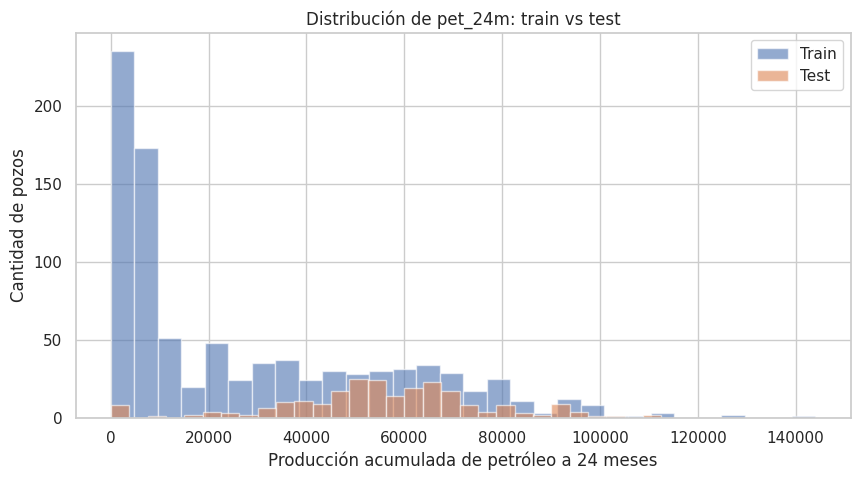

In [ ]:
plt.figure(figsize=(10, 5))

y_train.plot(
    kind="hist",
    bins=30,
    alpha=0.6,
    label="Train"
)

y_test.plot(
    kind="hist",
    bins=30,
    alpha=0.6,
    label="Test"
)

plt.title("Distribución de pet_24m: train vs test")
plt.xlabel("Producción acumulada de petróleo a 24 meses")
plt.ylabel("Cantidad de pozos")
plt.legend()
plt.show()

#### Resultado del modelo baseline

El modelo baseline, basado en la mediana del conjunto de entrenamiento, obtuvo un MAE de 23.016,66 en entrenamiento y de 43.060,73 en prueba.

El incremento considerable del error en el conjunto de prueba indica que una predicción constante basada en el comportamiento histórico no representa adecuadamente a los pozos más recientes.

El R² obtenido en prueba fue negativo (-4,17), lo que confirma que este modelo no posee capacidad predictiva útil sobre el conjunto temporal reservado.

Este resultado constituye el punto de referencia que deberán superar los modelos supervisados posteriores.

Debido a la diferencia observada entre entrenamiento y prueba, se analiza además la distribución temporal de la variable objetivo antes de continuar con modelos de mayor complejidad.

#### Diferencias temporales en la variable objetivo

La separación temporal evidencia una diferencia importante entre la distribución de producción acumulada de los pozos históricos utilizados para entrenamiento y la de los pozos más recientes reservados para prueba.

La producción media a 24 meses pasa de 28.037,03 en entrenamiento a 55.966,95 en prueba, mientras que la mediana aumenta de 13.844,50 a 55.592,23.

Además, el primer cuartil del conjunto de prueba (45.513,09) se aproxima al tercer cuartil del conjunto de entrenamiento (49.712,31).

Esto indica que el conjunto de prueba representa una cohorte productivamente diferente y más reciente. Por lo tanto, constituye una evaluación exigente de la capacidad de los modelos para generalizar temporalmente.

Esta diferencia debe considerarse al interpretar las métricas obtenidas y no se atribuye, por sí sola, a sobreajuste.

### 19.2 Regresión Lineal

Como primer modelo supervisado se utiliza una regresión lineal.

El objetivo es evaluar si existe una relación lineal entre las características técnicas y temporales disponibles al inicio del pozo y su producción acumulada de petróleo a 24 meses.

El modelo utiliza el mismo conjunto de entrenamiento, conjunto de prueba y pipeline de preprocesamiento empleado en el baseline, lo que permite comparar sus resultados directamente.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.base import clone

In [ ]:
modelo_lineal = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("modelo", LinearRegression())
    ]
)

In [ ]:
modelo_lineal.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['cota', 'profundidad_valida',
                                                   'duracion_perforacion_modelo',
                                                   'anio_inicio']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['area'])])),
                ('modelo', LinearRegression())])

In [ ]:
pred_lineal_train = modelo_lineal.predict(X_train)
pred_lineal_test = modelo_lineal.predict(X_test)

In [ ]:
resultado_lineal = evaluar_regresion(
    "Regresión Lineal",
    y_train,
    pred_lineal_train,
    y_test,
    pred_lineal_test
)

pd.DataFrame(
    [
        resultado_dummy,
        resultado_lineal
    ]
).round(2)

,modelo,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test
0,Dummy - Mediana,23016.66,43060.73,31792.01,46899.60,-0.25,-4.17
1,Regresión Lineal,8996.00,17588.08,12642.09,20953.95,0.80,-0.03


In [ ]:
print("Promedio real train:", round(y_train.mean(), 2))
print("Promedio predicho train:", round(pred_lineal_train.mean(), 2))

print("\nPromedio real test:", round(y_test.mean(), 2))
print("Promedio predicho test:", round(pred_lineal_test.mean(), 2))

Promedio real train: 28037.03
Promedio predicho train: 28037.03

Promedio real test: 55966.95
Promedio predicho test: 70362.76


#### Resultado de la Regresión Lineal

La Regresión Lineal mejora considerablemente respecto del modelo baseline.

En el conjunto de prueba, el MAE disminuye de 43.060,73 a 17.588,08 y el RMSE de 46.899,60 a 20.953,95. Esto indica que las variables utilizadas contienen información relevante para estimar la producción acumulada a 24 meses.

Sin embargo, se observa una diferencia importante entre el desempeño de entrenamiento y prueba. El modelo alcanza un R² de 0,80 en entrenamiento, mientras que en prueba obtiene un R² de -0,03.

Además, la producción media real del conjunto de prueba es de 55.966,95, mientras que la predicción media del modelo es de 70.362,76, evidenciando una tendencia a sobreestimar la producción de los pozos más recientes.

Estos resultados sugieren que las relaciones aprendidas sobre las cohortes históricas no generalizan completamente hacia el período más reciente. La diferencia puede estar asociada tanto al cambio temporal observado en la variable objetivo como a las limitaciones de un modelo estrictamente lineal.

### 19.3 Árbol de Decisión

Se utiliza un Árbol de Decisión para evaluar si relaciones no lineales entre las características disponibles permiten mejorar la predicción de `pet_24m`.

A diferencia de la Regresión Lineal, el árbol puede generar reglas diferentes para distintos grupos de pozos sin asumir una relación lineal entre las variables y la producción.

En esta primera instancia se entrena el modelo con sus parámetros por defecto. Posteriormente se analizará la diferencia entre entrenamiento y prueba para detectar posibles señales de sobreajuste.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

modelo_arbol = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "modelo",
            DecisionTreeRegressor(
                random_state=42
            )
        )
    ]
)

In [ ]:
modelo_arbol.fit(X_train, y_train)

pred_arbol_train = modelo_arbol.predict(X_train)
pred_arbol_test = modelo_arbol.predict(X_test)

In [ ]:
resultado_arbol = evaluar_regresion(
    "Árbol de Decisión",
    y_train,
    pred_arbol_train,
    y_test,
    pred_arbol_test
)

resultados_regresion = pd.DataFrame(
    [
        resultado_dummy,
        resultado_lineal,
        resultado_arbol
    ]
)

resultados_regresion.round(2)

,modelo,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test
0,Dummy - Mediana,23016.66,43060.73,31792.01,46899.60,-0.25,-4.17
1,Regresión Lineal,8996.00,17588.08,12642.09,20953.95,0.80,-0.03
2,Árbol de Decisión,0.00,18236.84,0.00,24287.08,1.00,-0.39


#### Resultado del Árbol de Decisión

El Árbol de Decisión presenta un ajuste perfecto sobre el conjunto de entrenamiento, con MAE y RMSE iguales a cero y un R² de 1,00.

Sin embargo, este desempeño no se mantiene sobre los datos de prueba. En test obtiene un MAE de 18.236,84, un RMSE de 24.287,08 y un R² de -0,39.

La diferencia extrema entre entrenamiento y prueba constituye una señal clara de **sobreajuste (overfitting)**: el árbol sin restricciones aprende en exceso las particularidades del conjunto de entrenamiento y pierde capacidad de generalización sobre pozos más recientes.

Aunque mejora ampliamente respecto del modelo baseline, su desempeño en test es inferior al obtenido por la Regresión Lineal.

Este resultado justifica evaluar modelos de ensamble y posteriormente ajustar hiperparámetros que controlen la complejidad del modelo.

### 19.4 Random Forest Regressor

Dado el sobreajuste observado en el Árbol de Decisión, se evalúa un modelo Random Forest.

Random Forest combina múltiples árboles de decisión y promedia sus predicciones, lo que permite reducir la variabilidad asociada a un único árbol y puede mejorar la capacidad de generalización.

En esta primera instancia se utiliza una configuración inicial sin optimización específica de hiperparámetros. Posteriormente se evaluará su desempeño mediante validación cruzada y se ajustarán los parámetros más relevantes.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

modelo_rf = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "modelo",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [ ]:
modelo_rf.fit(X_train, y_train)

pred_rf_train = modelo_rf.predict(X_train)
pred_rf_test = modelo_rf.predict(X_test)

In [ ]:
resultado_rf = evaluar_regresion(
    "Random Forest",
    y_train,
    pred_rf_train,
    y_test,
    pred_rf_test
)

resultados_regresion = pd.DataFrame(
    [
        resultado_dummy,
        resultado_lineal,
        resultado_arbol,
        resultado_rf
    ]
)

resultados_regresion.round(2)

,modelo,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test
0,Dummy - Mediana,23016.66,43060.73,31792.01,46899.60,-0.25,-4.17
1,Regresión Lineal,8996.00,17588.08,12642.09,20953.95,0.80,-0.03
2,Árbol de Decisión,0.00,18236.84,0.00,24287.08,1.00,-0.39
3,Random Forest,2608.35,13335.66,4272.32,17295.42,0.98,0.30


#### Resultado del Random Forest

Random Forest presenta el mejor desempeño de los modelos evaluados hasta el momento.

En el conjunto de prueba obtiene un MAE de 13.335,66, un RMSE de 17.295,42 y un R² de 0,30, mejorando claramente respecto del baseline, la Regresión Lineal y el Árbol de Decisión sin restricciones.

El modelo también alcanza un R² de 0,98 en entrenamiento, considerablemente superior al resultado obtenido en prueba. Esta diferencia indica que todavía existe sobreajuste: el modelo aprende con gran precisión las observaciones históricas, pero parte de ese aprendizaje no se generaliza completamente a las cohortes más recientes.

Aun así, Random Forest es hasta el momento el modelo con mayor capacidad predictiva sobre el conjunto temporal de prueba.

El siguiente paso consiste en evaluar su estabilidad mediante validación cruzada y ajustar hiperparámetros orientados a reducir el sobreajuste y mejorar la generalización.

## 20. Validación cruzada y análisis de sobreajuste

La evaluación sobre un único conjunto de prueba permite estimar la capacidad de generalización final, pero no es suficiente para seleccionar hiperparámetros.

Por este motivo se utiliza validación cruzada únicamente sobre el conjunto de entrenamiento.

Debido a la naturaleza temporal del problema, las observaciones se mantienen ordenadas según la fecha de inicio de actividad y se utiliza una estrategia de validación temporal, evitando que observaciones futuras sean utilizadas para entrenar modelos que luego son evaluados sobre períodos anteriores.

El conjunto de prueba final permanece completamente separado y no participa en esta etapa.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

In [ ]:

# Aseguramos orden temporal y un índice continuo
train_df = (
    train_df
    .sort_values("fecha_inicio_activo")
    .reset_index(drop=True)
)

# Volvemos a construir X_train e y_train
X_train = train_df[features_base].copy()
y_train = train_df["pet_24m"].copy()

# Fechas mensuales únicas de inicio
fechas_unicas = np.array(
    sorted(train_df["fecha_inicio_activo"].unique())
)

print("Cantidad de cohortes temporales:", len(fechas_unicas))

Cantidad de cohortes temporales: 122


In [ ]:
tscv_fechas = TimeSeriesSplit(n_splits=5)

cv_temporal = []

for fold, (idx_fechas_train, idx_fechas_val) in enumerate(
    tscv_fechas.split(fechas_unicas),
    start=1
):
    fechas_train = fechas_unicas[idx_fechas_train]
    fechas_val = fechas_unicas[idx_fechas_val]

    idx_train = np.where(
        train_df["fecha_inicio_activo"].isin(fechas_train)
    )[0]

    idx_val = np.where(
        train_df["fecha_inicio_activo"].isin(fechas_val)
    )[0]

    cv_temporal.append(
        (idx_train, idx_val)
    )

    fechas_compartidas = set(fechas_train).intersection(
        set(fechas_val)
    )

    print(
        f"Fold {fold}: "
        f"train={len(idx_train)} pozos | "
        f"validación={len(idx_val)} pozos | "
        f"fechas compartidas={len(fechas_compartidas)}"
    )

Fold 1: train=61 pozos | validación=235 pozos | fechas compartidas=0
Fold 2: train=296 pozos | validación=187 pozos | fechas compartidas=0
Fold 3: train=483 pozos | validación=89 pozos | fechas compartidas=0
Fold 4: train=572 pozos | validación=135 pozos | fechas compartidas=0
Fold 5: train=707 pozos | validación=206 pozos | fechas compartidas=0


In [ ]:
for fold, (idx_train, idx_val) in enumerate(
    cv_temporal,
    start=1
):
    max_train = train_df.iloc[
        idx_train
    ]["fecha_inicio_activo"].max()

    min_val = train_df.iloc[
        idx_val
    ]["fecha_inicio_activo"].min()

    print(
        f"Fold {fold}: "
        f"última fecha train = {max_train.date()} | "
        f"primera fecha validación = {min_val.date()} | "
        f"correcto = {max_train < min_val}"
    )


Fold 1: última fecha train = 2013-07-01 | primera fecha validación = 2013-08-01 | correcto = True
Fold 2: última fecha train = 2015-03-01 | primera fecha validación = 2015-04-01 | correcto = True
Fold 3: última fecha train = 2016-11-01 | primera fecha validación = 2016-12-01 | correcto = True
Fold 4: última fecha train = 2018-09-01 | primera fecha validación = 2018-10-01 | correcto = True
Fold 5: última fecha train = 2021-05-01 | primera fecha validación = 2021-06-01 | correcto = True


In [ ]:
scores_rf = cross_validate(
    modelo_rf,
    X_train,
    y_train,
    cv=cv_temporal,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

In [ ]:
resultados_cv_rf = pd.DataFrame({
    "MAE_train": -scores_rf["train_mae"],
    "MAE_validacion": -scores_rf["test_mae"],
    "R2_train": scores_rf["train_r2"],
    "R2_validacion": scores_rf["test_r2"]
})

resultados_cv_rf.round(2)

,MAE_train,MAE_validacion,R2_train,R2_validacion
0,1362.12,4456.45,0.81,-0.39
1,912.27,5635.94,0.90,0.57
2,1156.32,13074.09,0.96,0.37
3,1389.89,20900.78,0.97,0.13
4,2057.24,16610.01,0.97,0.34


In [ ]:
print("Promedio validación cruzada temporal")

print(
    "MAE train:",
    round(resultados_cv_rf["MAE_train"].mean(), 2)
)

print(
    "MAE validación:",
    round(resultados_cv_rf["MAE_validacion"].mean(), 2)
)

print(
    "R² train:",
    round(resultados_cv_rf["R2_train"].mean(), 2)
)

print(
    "R² validación:",
    round(resultados_cv_rf["R2_validacion"].mean(), 2)
)

Promedio validación cruzada temporal
MAE train: 1375.57
MAE validación: 12135.46
R² train: 0.92
R² validación: 0.2


### 20.1 Resultado de la validación cruzada temporal

La validación cruzada temporal confirma que el Random Forest presenta señales de sobreajuste.

En promedio, el modelo obtiene un MAE de 1.375,57 en entrenamiento y de 12.135,46 en validación. Asimismo, el R² promedio disminuye de 0,92 en entrenamiento a 0,20 en validación.

La diferencia entre ambos conjuntos indica que el modelo aprende con gran precisión los datos históricos utilizados durante el entrenamiento, pero pierde capacidad predictiva al aplicarse a cohortes temporales posteriores.

También se observa variabilidad entre los distintos folds. El R² de validación oscila entre -0,39 y 0,57, lo que indica que la capacidad de generalización del modelo depende del período temporal evaluado.

Estos resultados justifican realizar una optimización de hiperparámetros orientada a reducir la complejidad del Random Forest y mejorar su desempeño sobre datos no vistos.

El conjunto de prueba final continúa reservado y no participa en la selección de hiperparámetros.

## 21. Optimización de hiperparámetros

El Random Forest inicial presenta el mejor desempeño predictivo entre los modelos evaluados, pero la validación cruzada temporal evidencia una diferencia importante entre entrenamiento y validación.

Por este motivo se optimizan hiperparámetros relacionados con la complejidad de los árboles.

La búsqueda se realiza exclusivamente sobre el conjunto de entrenamiento utilizando los mismos folds temporales definidos previamente. El conjunto de prueba final permanece completamente separado.

La métrica seleccionada para la búsqueda es el MAE, por lo que se busca la configuración que minimice el error absoluto promedio sobre las cohortes de validación.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
parametros_rf = {
    "modelo__n_estimators": [
        200, 300, 500, 700
    ],

    "modelo__max_depth": [
        4, 6, 8, 10, 12, None
    ],

    "modelo__min_samples_split": [
        2, 5, 10, 20
    ],

    "modelo__min_samples_leaf": [
        1, 2, 4, 8, 12
    ],

    "modelo__max_features": [
        "sqrt", 0.5, 0.75, 1.0
    ]
}

In [ ]:
busqueda_rf = RandomizedSearchCV(
    estimator=modelo_rf,
    param_distributions=parametros_rf,
    n_iter=40,
    scoring="neg_mean_absolute_error",
    cv=cv_temporal,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [ ]:
busqueda_rf.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


RandomizedSearchCV(cv=[(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60]),
                        array([ 61,  62,  63,  64,  65,  66,  67,  68,  69,  70,  71,  72,  73,
        74,  75,  76,  77,  78,  79,  80,  81,  82,  83,  84,  85,  86,
        87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,  98,  99,
       100, 101, 102, 103, 104,...
                                                                    random_state=42))]),
                   n_iter=40, n_jobs=-1,
                   param_distributions={'modelo__max_depth': [4, 6, 8, 10, 12,
                                                              None],
                                        'modelo__max_features': ['sqrt', 0.5,
                                                                 0.75, 1.0],
                                        'modelo__min_samples_leaf': [1, 2, 4, 8,
                                                                     12],
                                        'modelo__min_samples_split': [2, 5, 10,
                                                                      20],
                                        'modelo__n_estimators': [200, 300, 500,
                                                                 700]},
                   random_state=42, return_train_score=True,
                   scoring='neg_mean_absolute_error', verbose=1)

In [ ]:
print("Mejores hiperparámetros:")

for parametro, valor in busqueda_rf.best_params_.items():
    print(f"{parametro}: {valor}")

print(
    "\nMejor MAE medio de validación:",
    round(-busqueda_rf.best_score_, 2)
)

Mejores hiperparámetros:
modelo__n_estimators: 200
modelo__min_samples_split: 2
modelo__min_samples_leaf: 1
modelo__max_features: 0.5
modelo__max_depth: 10

Mejor MAE medio de validación: 11805.48


### 21.1 Resultado de la optimización

La búsqueda de hiperparámetros seleccionó una configuración de Random Forest utilizando exclusivamente el conjunto de entrenamiento y los folds de validación temporal definidos previamente.

La selección no utiliza información del conjunto de prueba final.

A continuación se evalúa nuevamente la configuración seleccionada mediante validación cruzada temporal para determinar si reduce la diferencia entre entrenamiento y validación respecto del Random Forest inicial.

In [ ]:
print(
    "Mejor MAE medio de validación:",
    round(-busqueda_rf.best_score_, 2)
)

Mejor MAE medio de validación: 11805.48


In [ ]:
mejor_rf = busqueda_rf.best_estimator_

In [ ]:
scores_rf_optimizado = cross_validate(
    mejor_rf,
    X_train,
    y_train,
    cv=cv_temporal,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

In [ ]:
resultados_cv_rf_optimizado = pd.DataFrame({
    "MAE_train": -scores_rf_optimizado["train_mae"],
    "MAE_validacion": -scores_rf_optimizado["test_mae"],
    "R2_train": scores_rf_optimizado["train_r2"],
    "R2_validacion": scores_rf_optimizado["test_r2"]
})

resultados_cv_rf_optimizado.round(2)

,MAE_train,MAE_validacion,R2_train,R2_validacion
0,1326.02,4269.58,0.83,-0.33
1,1464.73,5524.39,0.81,0.58
2,1739.84,12978.72,0.94,0.37
3,2127.27,20535.10,0.95,0.18
4,3038.55,15719.64,0.96,0.38


In [ ]:
print("Random Forest optimizado - Promedios CV")

print(
    "MAE train:",
    round(resultados_cv_rf_optimizado["MAE_train"].mean(), 2)
)

print(
    "MAE validación:",
    round(resultados_cv_rf_optimizado["MAE_validacion"].mean(), 2)
)

print(
    "R² train:",
    round(resultados_cv_rf_optimizado["R2_train"].mean(), 2)
)

print(
    "R² validación:",
    round(resultados_cv_rf_optimizado["R2_validacion"].mean(), 2)
)

Random Forest optimizado - Promedios CV
MAE train: 1939.28
MAE validación: 11805.48
R² train: 0.9
R² validación: 0.24


In [ ]:
comparacion_rf = pd.DataFrame({
    "modelo": [
        "Random Forest inicial",
        "Random Forest optimizado"
    ],

    "MAE_train": [
        resultados_cv_rf["MAE_train"].mean(),
        resultados_cv_rf_optimizado["MAE_train"].mean()
    ],

    "MAE_validacion": [
        resultados_cv_rf["MAE_validacion"].mean(),
        resultados_cv_rf_optimizado["MAE_validacion"].mean()
    ],

    "R2_train": [
        resultados_cv_rf["R2_train"].mean(),
        resultados_cv_rf_optimizado["R2_train"].mean()
    ],

    "R2_validacion": [
        resultados_cv_rf["R2_validacion"].mean(),
        resultados_cv_rf_optimizado["R2_validacion"].mean()
    ]
})

comparacion_rf.round(2)

,modelo,MAE_train,MAE_validacion,R2_train,R2_validacion
0,Random Forest inicial,1375.57,12135.46,0.92,0.20
1,Random Forest optimizado,1939.28,11805.48,0.90,0.24


### 21.2 Comparación del modelo inicial y optimizado

La optimización de hiperparámetros produjo una mejora moderada en la capacidad de generalización del Random Forest.

El MAE promedio de validación disminuyó de 12.135,46 a 11.805,48, mientras que el R² promedio de validación aumentó de 0,20 a 0,24.

Al mismo tiempo, el desempeño sobre entrenamiento disminuyó levemente: el R² promedio pasó de 0,92 a 0,90. Este comportamiento es consistente con el objetivo de la optimización, ya que el modelo ajustado memoriza algo menos los datos de entrenamiento y mejora su desempeño sobre cohortes temporales no utilizadas durante el ajuste.

Sin embargo, continúa existiendo una diferencia importante entre entrenamiento y validación, por lo que el sobreajuste no desaparece completamente.

También se observa variabilidad entre los distintos períodos de validación. El R² oscila entre -0,33 y 0,58, indicando que la capacidad predictiva no es homogénea entre cohortes temporales.

Dado que el Random Forest optimizado presenta menor MAE y mayor R² promedio de validación que el modelo inicial, se selecciona esta configuración para la evaluación final sobre el conjunto de prueba.

## 22. Evaluación final del modelo de regresión

Luego de seleccionar el modelo utilizando exclusivamente el conjunto de entrenamiento y la validación cruzada temporal, se realiza una evaluación final sobre el conjunto de prueba.

Este conjunto contiene los pozos más recientes y no fue utilizado para seleccionar hiperparámetros.

La evaluación final permite estimar la capacidad del modelo seleccionado para generalizar hacia nuevas cohortes temporales.

In [ ]:
pred_rf_opt_train = mejor_rf.predict(X_train)
pred_rf_opt_test = mejor_rf.predict(X_test)

In [ ]:
resultado_rf_optimizado = evaluar_regresion(
    "Random Forest optimizado",
    y_train,
    pred_rf_opt_train,
    y_test,
    pred_rf_opt_test
)

comparacion_final_regresion = pd.DataFrame(
    [
        resultado_dummy,
        resultado_lineal,
        resultado_arbol,
        resultado_rf,
        resultado_rf_optimizado
    ]
)

comparacion_final_regresion.round(2)

,modelo,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test
0,Dummy - Mediana,23016.66,43060.73,31792.01,46899.60,-0.25,-4.17
1,Regresión Lineal,8996.00,17588.08,12642.09,20953.95,0.80,-0.03
2,Árbol de Decisión,0.00,18236.84,0.00,24287.08,1.00,-0.39
3,Random Forest,2608.35,13335.66,4272.32,17295.42,0.98,0.30
4,Random Forest optimizado,4267.94,12910.85,6631.53,16559.89,0.95,0.36


In [ ]:
print(
    "Promedio real test:",
    round(y_test.mean(), 2)
)

print(
    "Promedio predicho test:",
    round(pred_rf_opt_test.mean(), 2)
)

print(
    "Mediana real test:",
    round(y_test.median(), 2)
)

print(
    "Mediana predicha test:",
    round(np.median(pred_rf_opt_test), 2)
)

Promedio real test: 55966.95
Promedio predicho test: 63735.89
Mediana real test: 55592.23
Mediana predicha test: 64685.76


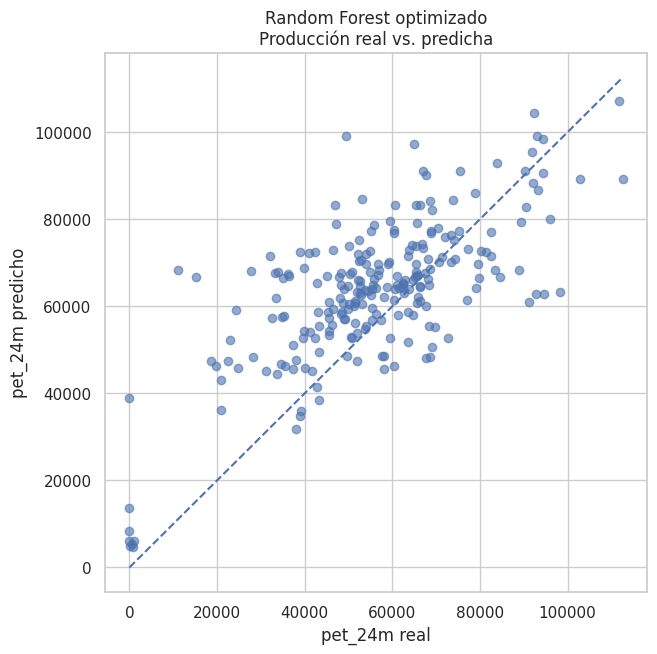

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    pred_rf_opt_test,
    alpha=0.6
)

limite_min = min(
    y_test.min(),
    pred_rf_opt_test.min()
)

limite_max = max(
    y_test.max(),
    pred_rf_opt_test.max()
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("pet_24m real")
plt.ylabel("pet_24m predicho")

plt.title(
    "Random Forest optimizado\n"
    "Producción real vs. predicha"
)

plt.show()

### 22.1 Resultado final del modelo de regresión

Luego de la optimización de hiperparámetros, el Random Forest optimizado presenta el mejor desempeño sobre el conjunto de prueba.

El modelo obtiene un MAE de 12.910,85, un RMSE de 16.559,89 y un R² de 0,36.

Respecto del Random Forest inicial, se observa una mejora en las tres métricas de prueba: disminuyen MAE y RMSE y aumenta el R².

Al mismo tiempo, el error de entrenamiento aumenta respecto del modelo inicial, lo que indica que la optimización redujo parcialmente la tendencia a memorizar los datos históricos.

Sin embargo, persiste una diferencia importante entre el desempeño de entrenamiento y prueba, por lo que el modelo continúa presentando cierto grado de sobreajuste y una capacidad de generalización limitada por las diferencias temporales observadas entre las cohortes.

Dentro de los modelos evaluados, el Random Forest optimizado se selecciona como el modelo de regresión final.

## 23. Modelo de clasificación

Además del problema de regresión, se aborda una tarea de clasificación supervisada utilizando la misma variable de producción acumulada a 24 meses.

El objetivo consiste en clasificar los pozos en dos grupos:

- **0 — Producción baja**
- **1 — Producción alta**

El umbral de separación se define utilizando exclusivamente la mediana de `pet_24m` del conjunto de entrenamiento.

De esta manera, el conjunto de prueba no participa en la construcción de la variable objetivo de clasificación y se evita fuga de información.

In [ ]:
umbral_clasificacion = y_train.median()

print(
    "Umbral de clasificación:",
    round(umbral_clasificacion, 2)
)

Umbral de clasificación: 13844.5


In [ ]:
y_train_clas = (
    y_train >= umbral_clasificacion
).astype(int)

y_test_clas = (
    y_test >= umbral_clasificacion
).astype(int)

In [ ]:
print("TRAIN")
print(y_train_clas.value_counts())
print(
    y_train_clas.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTEST")
print(y_test_clas.value_counts())
print(
    y_test_clas.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

TRAIN
pet_24m
1    457
0    456
Name: count, dtype: int64
pet_24m
1    50.05
0    49.95
Name: proportion, dtype: float64

TEST
pet_24m
1    228
0      9
Name: count, dtype: int64
pet_24m
1    96.2
0     3.8
Name: proportion, dtype: float64
